# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** [Patrich Moratti Manurung]
- **Email:** [ptmoratti29@gmail.com]
- **ID Dicoding:** [moratti]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menjadi 10 penyumbang pendapatan terbesar, beserta persentase kontribusinya terhadap total pendapatan selama Januari 2017 sampai Agustus 2018?
- **Pertanyaan 2:** Bagaimana tren pendapatan per bulan selama Januari 2017 sampai Agustus 2018, termasuk bulan puncak dan pertumbuhan persentasenya?
- **Pertanyaan 3:** Negara bagian mana yang termasuk 5 teratas dengan persentase pesanan terlambat tertinggi selama Januari 2017 sampai Agustus 2018?
- **Pertanyaan 4:** Berapa penurunan rata-rata skor ulasan pada pesanan yang terlambat 1 sampai 3 hari, 4 sampai 7 hari, atau lebih dari 7 hari dibandingkan pesanan tepat waktu selama Januari 2017 sampai Agustus 2018?
- **Pertanyaan 5:** Segmen pelanggan RFM (recency, frequency, monetary) mana yang menyumbang pendapatan terbesar pada pembelian Januari 2017 sampai Agustus 2018?

## Import Semua Packages/Library yang Digunakan

In [360]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import geopandas as gpd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load df customers_df, geolocation_df, order_items_df, order_payments_df, order_reviews_df, orders_df, products_df, sellers_df, category_translation_df 

In [361]:
customers_df = pd.read_csv("data/customers_dataset.csv")
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_payments_df = pd.read_csv("data/order_payments_dataset.csv")
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
sellers_df = pd.read_csv("data/sellers_dataset.csv")
category_translation_df = pd.read_csv("data/product_category_name_translation.csv")

dfs = {
    "customers": customers_df, "geolocation": geolocation_df,
    "order_items": order_items_df, "order_payments": order_payments_df,
    "order_reviews": order_reviews_df, "orders": orders_df,
    "products": products_df, "sellers": sellers_df,
    "category_translation": category_translation_df,
}

for nama, df in dfs.items():
    print(f"{nama:<22} {df.shape}")

customers              (99441, 5)
geolocation            (1000163, 5)
order_items            (112650, 7)
order_payments         (103886, 5)
order_reviews          (99224, 7)
orders                 (99441, 8)
products               (32951, 9)
sellers                (3095, 4)
category_translation   (71, 2)


**Insight:**
- Sembilan tabel berhasil dimuat. Jumlah barisnya: customers 99.441, geolocation 1.000.163, order_items 112.650, order_payments 103.886, order_reviews 99.224, orders 99.441, products 32.951, sellers 3.095, dan category_translation 71.
- Tabel geolocation adalah yang terbesar (lebih dari satu juta baris), sedangkan category_translation yang terkecil (71 baris).
- Tabel orders dan customers sama-sama berisi 99.441 baris, karena setiap pesanan memiliki satu baris `customer_id`.

### Assessing Data

#### Identifying customers_df problem

In [362]:
customers_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [363]:
customers_df.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [364]:
print("jumlah duplikasi: ", customers_df.duplicated().sum())
print("jumlah customer_id        :", customers_df.customer_id.nunique())
print("jumlah customer_unique_id :", customers_df.customer_unique_id.nunique())

jumlah duplikasi:  0
jumlah customer_id        : 99441
jumlah customer_unique_id : 96096


**Steps to Take:**
- Tidak ada langkah cleaning yang diperlukan untuk tabel ini karena tidak ada missing value maupun duplikasi.
- Tabel ini dipakai apa adanya. Untuk menghitung jumlah pelanggan, gunakan `customer_unique_id`, bukan `customer_id`.

**Insight:**
- Tabel memiliki 99.441 baris dan 5 kolom. Tidak ada missing value dan tidak ada baris duplikat (jumlah duplikasi = 0).
- Terdapat 99.441 nilai `customer_id` unik, sama dengan jumlah baris. Artinya `customer_id` dibuat baru untuk setiap pesanan.
- Hanya ada 96.096 nilai `customer_unique_id` unik. Artinya ada pelanggan yang membeli lebih dari satu kali. `customer_unique_id` adalah identitas pelanggan yang sebenarnya.

#### Identifying geolocation_df problems

In [365]:
geolocation_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB


In [366]:
geolocation_df.isna().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [367]:
print("jumlah duplikasi: ", geolocation_df.duplicated().sum())
print("jumlah kode pos unik:", geolocation_df.geolocation_zip_code_prefix.nunique())

jumlah duplikasi:  261831
jumlah kode pos unik: 19015


In [368]:
geolocation_df.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02


In [369]:
diluar_brasil = geolocation_df[(geolocation_df.geolocation_lat > 5.27) | (geolocation_df.geolocation_lat < -33.75) |
                               (geolocation_df.geolocation_lng > -34.79) | (geolocation_df.geolocation_lng < -73.99)]
print("jumlah titik di luar Brasil:", len(diluar_brasil))
diluar_brasil.head()

jumlah titik di luar Brasil: 42


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ


In [370]:
geolocation_df.geolocation_city.value_counts().head(10)

geolocation_city
sao paulo                135800
rio de janeiro            62151
belo horizonte            27805
são paulo                 24918
curitiba                  16593
porto alegre              13521
salvador                  11865
guarulhos                 11340
brasilia                  10470
sao bernardo do campo      8112
Name: count, dtype: int64

**Steps to Take:**
1. Hapus aksen pada kolom `geolocation_city` agar penulisan "são paulo" dan "sao paulo" menjadi seragam.
2. Hapus baris duplikat. Langkah ini dilakukan setelah aksen dihapus supaya baris yang menjadi kembar akibat penyeragaman nama kota ikut terhapus.
3. Hapus titik koordinat yang berada di luar wilayah Brasil.
4. Ringkas data menjadi satu baris per kode pos (rata-rata latitude dan longitude) dalam tabel `geolocation_zip_df`, agar bisa digabung dengan customers dan sellers tanpa menggandakan baris.

**Insight:**
- Tabel memiliki 1.000.163 baris dan tidak ada missing value.
- Terdapat 261.831 baris duplikat (sekitar 26% dari seluruh baris).
- Hanya ada 19.015 kode pos unik, padahal barisnya lebih dari satu juta. Jadi satu kode pos punya banyak titik koordinat, dan tabel ini tidak bisa langsung digabung dengan tabel lain.
- Terdapat 42 titik yang berada di luar batas wilayah Brasil, sehingga koordinatnya tidak valid.
- Nama kota ditulis tidak seragam. Contohnya "sao paulo" muncul 135.800 kali, sedangkan "são paulo" muncul 24.918 kali, padahal keduanya kota yang sama.

#### Identifying orders_df problems

In [371]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [372]:
orders_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [373]:
print("jumlah duplikasi: ", orders_df.duplicated().sum())
orders_df.order_status.value_counts()

jumlah duplikasi:  0


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [374]:
# apakah tanggal terima yang kosong itu wajar? melihat status pesanannya
orders_df[orders_df.order_delivered_customer_date.isna()].order_status.value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [375]:
# pesanan berstatus delivered tetapi tanggal terimanya kosong (kontradiksi)
orders_df[(orders_df.order_status == "delivered") & (orders_df.order_delivered_customer_date.isna())][
    ["order_id", "order_status", "order_delivered_carrier_date", "order_delivered_customer_date"]]

,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-30 18:12:23,NaN
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-25 08:05:00,NaN
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-03 13:57:00,NaN
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-03 13:57:00,NaN
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-03 09:28:00,NaN
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,NaN,NaN
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-12 14:10:00,NaN
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-07-03 19:26:00,NaN


In [376]:
approved = pd.to_datetime(orders_df.order_approved_at)
carrier = pd.to_datetime(orders_df.order_delivered_carrier_date)
customer = pd.to_datetime(orders_df.order_delivered_customer_date)

print("dikirim ke kurir sebelum pesanan disetujui :", (carrier < approved).sum())
print("sampai ke pelanggan sebelum diserahkan kurir:", (customer < carrier).sum())
print("berstatus canceled tetapi punya tanggal terima:", ((orders_df.order_status == "canceled") & orders_df.order_delivered_customer_date.notna()).sum())

dikirim ke kurir sebelum pesanan disetujui : 1359
sampai ke pelanggan sebelum diserahkan kurir: 23
berstatus canceled tetapi punya tanggal terima: 6


In [377]:
orders_df[~orders_df.order_id.isin(order_items_df.order_id)].order_status.value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

**Steps to Take:**
1. Ubah lima kolom tanggal (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) dari teks menjadi `datetime`.
2. Hapus pesanan berstatus `delivered` yang tidak memiliki tanggal diterima pelanggan, karena datanya tidak lengkap dan tidak bisa dipakai menghitung waktu pengiriman.
3. Hapus pesanan yang tanggal diterima pelanggannya lebih awal daripada tanggal diserahkan ke kurir, karena urutan waktunya tidak masuk akal.
4. Missing value pada pesanan yang belum selesai (misalnya `shipped`, `canceled`, `unavailable`) dibiarkan, karena kosong memang wajar untuk pesanan yang belum sampai.

**Insight:**
- Tabel memiliki 99.441 baris, tidak ada duplikasi, dan semua kolom tanggal masih bertipe teks.
- Status pesanan: `delivered` 96.478, `shipped` 1.107, `canceled` 625, `unavailable` 609, `invoiced` 314, `processing` 301, `created` 5, dan `approved` 2. Mayoritas pesanan sudah terkirim.
- Missing value: `order_approved_at` 160, `order_delivered_carrier_date` 1.783, dan `order_delivered_customer_date` 2.965. Sebagian besar kosong karena pesanan belum sampai ke pelanggan.
- Ada 8 pesanan berstatus `delivered` tetapi tanggal diterimanya kosong.
- Ada 23 pesanan yang tiba di pelanggan sebelum diserahkan ke kurir.
- Ada 1.359 pesanan yang diserahkan ke kurir sebelum disetujui. Jumlahnya besar, sehingga dianggap sebagai ketidakselarasan pencatatan waktu dan tidak dihapus.
- Ada 6 pesanan berstatus `canceled` tetapi memiliki tanggal diterima.
- Sebanyak 775 pesanan tidak memiliki item di tabel order_items, kebanyakan berstatus `unavailable` (603) dan `canceled` (164).

#### Identifying order_items_df problems

In [378]:
order_items_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [379]:
order_items_df.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [380]:
order_items_df.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [381]:
print("jumlah duplikasi: ", order_items_df.duplicated().sum())

jumlah duplikasi:  0


In [382]:
print("jumlah item dengan ongkir 0:", (order_items_df.freight_value == 0).sum())
order_items_df.sort_values(by="price", ascending=False).head()[["order_id", "price", "freight_value"]]

jumlah item dengan ongkir 0: 383


,order_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,6735.0,194.31
112233,fefacc66af859508bf1a7934eab1e97f,6729.0,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,6499.0,227.66
74336,a96610ab360d42a2e5335a3998b4718a,4799.0,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,4690.0,74.34


**Steps to Take:**
1. Ubah kolom `shipping_limit_date` dari teks menjadi `datetime`.
2. Tidak ada baris yang dihapus. Harga tinggi dan ongkir 0 dianggap nilai asli, bukan kesalahan.

**Insight:**
- Tabel memiliki 112.650 baris, tanpa missing value dan tanpa baris duplikat.
- Kolom `shipping_limit_date` masih bertipe teks.
- Harga item rata-rata 120,65 dan mediannya 74,99, sedangkan harga tertinggi mencapai 6.735. Rata-rata yang jauh di atas median menunjukkan sebaran harga miring ke kanan, dengan sedikit barang sangat mahal.
- Harga tertinggi (6.735, 6.729, 6.499, 4.799, dan 4.690) disertai ongkir yang tinggi pula, sehingga terlihat sebagai barang mahal yang nyata dan bukan salah input.
- Ada 383 item dengan ongkir 0. Nilai ini diperlakukan sebagai ongkir gratis.
- Satu pesanan dapat berisi beberapa item, dengan `order_item_id` maksimum 21.

#### Identifying order_payments_df problems

In [383]:
order_payments_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [384]:
print("jumlah missing value:", order_payments_df.isna().sum().sum())
print("jumlah duplikasi: ", order_payments_df.duplicated().sum())
order_payments_df.describe()

jumlah missing value: 0
jumlah duplikasi:  0


,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [385]:
order_payments_df.payment_type.value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [386]:
# nilai pembayaran 0 atau cicilan 0 dianggap mencurigakan
order_payments_df[(order_payments_df.payment_value == 0) | (order_payments_df.payment_installments == 0)]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.00
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.00
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.00
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00


**Steps to Take:**
1. Hapus 9 baris dengan `payment_value` bernilai 0 (6 voucher dan 3 `not_defined`), karena tidak mewakili transaksi yang sebenarnya.
2. Ubah `payment_installments` bernilai 0 pada pembayaran kartu kredit menjadi 1, karena pembayaran kartu kredit minimal satu kali cicilan.
3. Buat tabel `payments_per_order_df` berisi total pembayaran per `order_id`, karena satu pesanan bisa dibayar dengan beberapa metode atau urutan.

**Insight:**
- Tabel memiliki 103.886 baris, tanpa missing value dan tanpa baris duplikat.
- Metode pembayaran: `credit_card` 76.795, `boleto` 19.784, `voucher` 5.775, `debit_card` 1.529, dan `not_defined` 3. Kartu kredit paling dominan.
- Ada 11 baris mencurigakan: 9 baris dengan `payment_value` 0 (6 `voucher` dan 3 `not_defined`) dan 2 baris `credit_card` dengan cicilan 0.
- `payment_sequential` maksimum 29, artinya sebuah pesanan dapat dibayar dalam banyak tahap. Jadi satu pesanan dapat muncul di banyak baris.

#### Identifying order_reviews_df problems

In [387]:
order_reviews_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [388]:
order_reviews_df.isna().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [389]:
print("jumlah duplikasi baris:", order_reviews_df.duplicated().sum())
print("review_id yang terulang:", order_reviews_df.review_id.duplicated().sum())
print("order_id yang terulang :", order_reviews_df.order_id.duplicated().sum())

jumlah duplikasi baris: 0
review_id yang terulang: 814
order_id yang terulang : 551


In [390]:
# contoh pesanan yang punya lebih dari satu ulasan
order_reviews_df[order_reviews_df.order_id.duplicated(keep=False)].sort_values(by="order_id")[
    ["review_id", "order_id", "review_score", "review_creation_date"]].head(6)

,review_id,order_id,review_score,review_creation_date
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,2017-08-29 00:00:00
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,2017-08-25 00:00:00
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,2018-02-22 00:00:00
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,2018-03-04 00:00:00
854,830636803620cdf8b6ffaf1b2f6e92b2,0176a6846bcb3b0d3aa3116a9a768597,5,2017-12-30 00:00:00
83224,d8e8c42271c8fb67b9dad95d98c8ff80,0176a6846bcb3b0d3aa3116a9a768597,5,2017-12-30 00:00:00


In [391]:
order_reviews_df.review_score.value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

**Steps to Take:**
1. Ubah kolom `review_creation_date` dan `review_answer_timestamp` dari teks menjadi `datetime`.
2. Pertahankan hanya satu ulasan per pesanan, yaitu ulasan terbaru (urutkan berdasarkan tanggal, lalu hapus duplikat `order_id` dengan `keep="last"`), agar satu pesanan tidak dihitung lebih dari sekali saat tabel digabung.
3. Kolom `review_comment_title` dan `review_comment_message` yang kosong dibiarkan, karena pelanggan memang tidak wajib menulis komentar.

**Insight:**
- Tabel memiliki 99.224 baris dan tidak ada baris yang sepenuhnya duplikat.
- Kolom `review_comment_title` kosong sebanyak 87.656 dan `review_comment_message` kosong sebanyak 58.247. Sebagian besar pelanggan hanya memberi skor tanpa komentar.
- `review_id` terulang 814 kali dan `order_id` terulang 551 kali. Artinya ada pesanan yang memiliki lebih dari satu ulasan.
- Skor ulasan 1 sampai 5: 11.424, 3.151, 8.179, 19.142, dan 57.328. Mayoritas pelanggan memberi skor 5.

#### Identifying products_df problems

In [392]:
products_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [393]:
products_df.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [394]:
print("jumlah duplikasi: ", products_df.duplicated().sum())
products_df.describe()

jumlah duplikasi:  0


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [395]:
# berat 0 gram mustahil untuk barang fisik
products_df[products_df.product_weight_g == 0][
    ["product_id", "product_category_name", "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]]

,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0.0,30.0,25.0,30.0


In [396]:
produk_bermasalah = products_df[products_df.product_weight_g.isna() | (products_df.product_weight_g == 0)]
print("jumlah produk dengan berat kosong atau 0 gram:", len(produk_bermasalah))
print("jumlah item pesanan yang memakai produk tersebut:", order_items_df.product_id.isin(produk_bermasalah.product_id).sum())

jumlah produk dengan berat kosong atau 0 gram: 6
jumlah item pesanan yang memakai produk tersebut: 26


In [397]:
# contoh produk yang kategorinya kosong
products_df[products_df.product_category_name.isna()].head()[
    ["product_id", "product_category_name", "product_name_lenght", "product_photos_qty", "product_weight_g"]]

,product_id,product_category_name,product_name_lenght,product_photos_qty,product_weight_g
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,650.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,300.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,200.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,18500.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,300.0


In [398]:
# kategori di tabel produk yang tidak ada di tabel terjemahan
kategori_produk = set(products_df.product_category_name.dropna())
kategori_terjemahan = set(category_translation_df.product_category_name)
print("kategori tanpa terjemahan:", kategori_produk - kategori_terjemahan)

kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


**Steps to Take:**
1. Perbaiki penulisan nama kolom `product_name_lenght` dan `product_description_lenght` menjadi `product_name_length` dan `product_description_length`.
2. Isi kategori yang kosong dengan `unknown`, agar produk tanpa kategori tetap dapat dianalisis.
3. Ubah berat produk bernilai 0 menjadi `NaN`. Barisnya tidak dihapus karena produk tersebut dipakai pada 26 item pesanan.

**Insight:**
- Tabel memiliki 32.951 baris dan tidak ada baris duplikat.
- Terdapat 610 produk tanpa kategori. Kolom nama, deskripsi, dan jumlah foto juga kosong pada 610 produk yang sama.
- Hanya 2 produk yang berat dan dimensinya kosong.
- Ada 4 produk dengan berat 0 gram, padahal dimensinya terisi (contohnya kategori `cama_mesa_banho` 30 x 25 x 30 cm). Jadi nilai 0 ini tidak masuk akal dan perlu dianggap data hilang.
- Total ada 6 produk dengan berat kosong atau 0 gram, dan produk-produk itu dipakai oleh 26 item pesanan. Jika barisnya dihapus, 26 item pesanan itu ikut kehilangan data produk.
- Terdapat 2 kategori produk yang tidak punya terjemahan di tabel category_translation: `pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`.

#### Identifying sellers_df problems

In [399]:
sellers_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 96.8 KB


In [400]:
print("jumlah missing value:", sellers_df.isna().sum().sum())
print("jumlah duplikasi: ", sellers_df.duplicated().sum())

jumlah missing value: 0
jumlah duplikasi:  0


In [401]:
nama_kota_aneh = sellers_df[sellers_df.seller_city.str.contains("[^a-z '-]")]
print("jumlah nama kota tidak standar:", len(nama_kota_aneh))
nama_kota_aneh.head(10)[["seller_city", "seller_state"]]

jumlah nama kota tidak standar: 24


,seller_city,seller_state
237,auriflama/sp,SP
246,sao paulo / sao paulo,SP
360,são paulo,SP
476,santa barbara d´oeste,SP
517,04482255,RJ
551,"novo hamburgo, rio grande do sul, brasil",RS
622,cariacica / es,ES
869,sbc/sp,SP
874,arraial d'ajuda (porto seguro),BA
945,santo andre/sao paulo,SP


**Steps to Take:**
1. Hapus aksen pada kolom `seller_city`, seperti yang dilakukan pada geolocation_df.
2. Bandingkan setiap nama kota dengan daftar nama kota pada geolocation_df. Nama yang tidak dikenali diganti dengan nama kota milik kode pos penjual tersebut. Cara ini dilakukan otomatis dengan referensi data, bukan perbaikan manual satu per satu.

**Insight:**
- Tabel memiliki 3.095 baris, tanpa missing value dan tanpa baris duplikat.
- Ada 24 nama kota yang tidak standar, misalnya mengandung tanda `/`, tanda `-`, nama negara bagian, angka, atau alamat email.
- Nama-nama tersebut membuat satu kota bisa tercatat dengan beberapa penulisan, sehingga analisis per kota tidak akurat.

#### Identifying category_translation_df problems

In [402]:
category_translation_df.info()
print("jumlah duplikasi: ", category_translation_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          71 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 1.2 KB
jumlah duplikasi:  0


**Steps to Take:**
- Tambahkan 3 kategori yang belum ada: `pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`, dan `unknown`, supaya semua kategori pada products_df punya terjemahan bahasa Inggris.

**Insight:**
- Tabel hanya memiliki 71 baris, tanpa missing value dan tanpa duplikasi.
- Dua kategori pada products_df belum tercakup dalam tabel ini (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`).
- Kategori `unknown` juga perlu ditambahkan karena akan dipakai untuk produk tanpa kategori.

### Cleaning Data

#### Fixing geolocation_df problems

perbaikan: (1) hapus aksen pada nama kota, (2) hapus baris duplikat, (3) buang titik di luar Brasil, dan (4) ringkas menjadi satu baris per kode pos

In [403]:
# 1. Hapus aksen pada nama kota
geolocation_df["geolocation_city"] = (geolocation_df["geolocation_city"]
                                      .str.replace("´", "'")
                                      .str.normalize("NFKD")
                                      .str.encode("ascii", errors="ignore")
                                      .str.decode("utf-8"))
geolocation_df.geolocation_city.value_counts().head(5)

geolocation_city
sao paulo         160719
rio de janeiro     62151
belo horizonte     27805
curitiba           16593
porto alegre       13521
Name: count, dtype: int64

In [404]:
# 2. Hapus baris duplikat
print("baris sebelum:", len(geolocation_df))
print("jumlah duplikasi sebelum:", geolocation_df.duplicated().sum())
geolocation_df = geolocation_df.drop_duplicates()
print("jumlah duplikasi sesudah:", geolocation_df.duplicated().sum())
print("baris sesudah:", len(geolocation_df))

baris sebelum: 1000163
jumlah duplikasi sebelum: 279668
jumlah duplikasi sesudah: 0
baris sesudah: 720495


In [405]:
# 3. Buang titik di luar Brasil
print("baris sebelum:", len(geolocation_df))
geolocation_df = geolocation_df[(geolocation_df.geolocation_lat <= 5.27) & (geolocation_df.geolocation_lat >= -33.75) &
                                (geolocation_df.geolocation_lng <= -34.79) & (geolocation_df.geolocation_lng >= -73.99)]
print("baris sesudah:", len(geolocation_df))
geolocation_df[["geolocation_lat", "geolocation_lng"]].describe().loc[["min", "max"]]

baris sebelum: 720495
baris sesudah: 720462


,geolocation_lat,geolocation_lng
min,-33.692616,-72.930746
max,4.482242,-34.793685


In [406]:
# 4. Ringkas menjadi satu baris per kode pos
geolocation_zip_df = geolocation_df.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean().reset_index()
print("jumlah baris:", len(geolocation_zip_df))
geolocation_zip_df.head()

jumlah baris: 19010


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,1001,-23.550271,-46.634047
1,1002,-23.547657,-46.634991
2,1003,-23.548991,-46.635653
3,1004,-23.549829,-46.634792
4,1005,-23.549487,-46.636650


#### Fixing orders_df problems

perbaikan: (1) mengubah lima kolom tanggal menjadi `datetime`, (2) menghapus pesanan `delivered` yang tidak punya tanggal diterima, (3) menghapus pesanan yang tanggal diterimanya lebih awal daripada tanggal diserahkan ke kurir

In [407]:
datetime_columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                    "order_delivered_customer_date", "order_estimated_delivery_date"]

for column in datetime_columns:
    orders_df[column] = pd.to_datetime(orders_df[column])

In [408]:
print("baris sebelum:", len(orders_df))
delivered_tanpa_tanggal = orders_df[(orders_df.order_status == "delivered") & (orders_df.order_delivered_customer_date.isna())]
orders_df = orders_df.drop(delivered_tanpa_tanggal.index)
print("delivered tanpa tanggal terima:", ((orders_df.order_status == "delivered") & (orders_df.order_delivered_customer_date.isna())).sum())
print("baris sesudah:", len(orders_df))

baris sebelum: 99441
delivered tanpa tanggal terima: 0
baris sesudah: 99433


In [409]:
tiba_sebelum_kurir = orders_df[orders_df.order_delivered_customer_date < orders_df.order_delivered_carrier_date]
orders_df = orders_df.drop(tiba_sebelum_kurir.index)
print("tiba sebelum diserahkan ke kurir:", (orders_df.order_delivered_customer_date < orders_df.order_delivered_carrier_date).sum())
print("baris sesudah:", len(orders_df))

tiba sebelum diserahkan ke kurir: 0
baris sesudah: 99410


#### Fixing order_items_df problems

perbaikan: (1) mengubah kolom `shipping_limit_date` menjadi `datetime`

In [410]:
order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])
print(order_items_df.dtypes["shipping_limit_date"], len(order_items_df))

datetime64[us] 112650


#### Fixing order_payments_df problems

perbaikan: (1) menghapus pembayaran bernilai 0, (2) mengubah cicilan 0 menjadi 1, (3) membuat total pembayaran per pesanan

In [411]:
print("baris sebelum:", len(order_payments_df))
order_payments_df = order_payments_df[order_payments_df.payment_value != 0]
print("payment_value minimum:", order_payments_df.payment_value.min())
print("baris sesudah:", len(order_payments_df))

baris sebelum: 103886
payment_value minimum: 0.01
baris sesudah: 103877


In [412]:
order_payments_df.loc[order_payments_df.payment_installments == 0, "payment_installments"] = 1
print("payment_installments minimum:", order_payments_df.payment_installments.min())

payment_installments minimum: 1


In [413]:
payments_per_order_df = order_payments_df.groupby("order_id").payment_value.sum().reset_index()
payments_per_order_df = payments_per_order_df.rename(columns={"payment_value": "total_payment"})
print("jumlah pesanan:", len(payments_per_order_df))
print("order_id yang terulang:", payments_per_order_df.order_id.duplicated().sum())

jumlah pesanan: 99437
order_id yang terulang: 0


#### Fixing order_reviews_df problems

perbaikan: (1) mengubah kolom tanggal menjadi `datetime`, (2) menyisakan satu ulasan terbaru untuk setiap pesanan

In [414]:
for column in ["review_creation_date", "review_answer_timestamp"]:
    order_reviews_df[column] = pd.to_datetime(order_reviews_df[column])
print(order_reviews_df.dtypes[["review_creation_date", "review_answer_timestamp"]])

review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


In [415]:
print("baris sebelum:", len(order_reviews_df))
order_reviews_df = (order_reviews_df
                    .sort_values(by=["review_creation_date", "review_answer_timestamp"])
                    .drop_duplicates(subset="order_id", keep="last"))
print("order_id yang terulang:", order_reviews_df.order_id.duplicated().sum())
print("baris sesudah:", len(order_reviews_df))

baris sebelum: 99224
order_id yang terulang: 0
baris sesudah: 98673


#### Fixing products_df problems

perbaikan: (1) memperbaiki ejaan nama kolom, (2) mengisi kategori kosong dengan `unknown`, (3) mengubah berat 0 gram menjadi `NaN`

In [416]:
products_df = products_df.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length"
})
print(list(products_df.columns))

['product_id', 'product_category_name', 'product_name_length', 'product_description_length', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [417]:
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
print("kategori kosong:", products_df.product_category_name.isna().sum())
print("produk tanpa kategori (unknown):", (products_df.product_category_name == "unknown").sum())

kategori kosong: 0
produk tanpa kategori (unknown): 610


In [418]:
products_df["product_weight_g"] = products_df["product_weight_g"].replace(0, np.nan)
print("berat 0 gram:", (products_df.product_weight_g == 0).sum())
products_df.isna().sum()

berat 0 gram: 0


product_id                      0
product_category_name           0
product_name_length           610
product_description_length    610
product_photos_qty            610
product_weight_g                6
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

#### Fixing sellers_df problems

perbaikan: (1) menghapus aksen pada nama kota, lalu mengganti nama kota yang tidak dikenali dengan nama kota dari kode pos penjual tersebut, (2) memakai geolocation_df sebagai referensi

In [419]:
sellers_df["seller_city"] = (sellers_df["seller_city"]
                             .str.replace("´", "'")
                             .str.normalize("NFKD")
                             .str.encode("ascii", errors="ignore")
                             .str.decode("utf-8"))

In [420]:
kota_valid = set(geolocation_df.geolocation_city)
kota_per_kodepos = (geolocation_df.drop_duplicates(subset="geolocation_zip_code_prefix")
                    .set_index("geolocation_zip_code_prefix").geolocation_city)

tidak_standar = ~sellers_df.seller_city.isin(kota_valid)
kota_lama = sellers_df.loc[tidak_standar, "seller_city"].copy()

print("jumlah kota unik sebelum:", sellers_df.seller_city.nunique())
print("jumlah nama kota tidak dikenali:", tidak_standar.sum())

sellers_df.loc[tidak_standar, "seller_city"] = sellers_df.loc[tidak_standar, "seller_zip_code_prefix"].map(kota_per_kodepos)
print("jumlah kota unik sesudah:", sellers_df.seller_city.nunique())

jumlah kota unik sebelum: 609
jumlah nama kota tidak dikenali: 64
jumlah kota unik sesudah: 556


In [421]:
print("nama kota tidak dikenali:", (~sellers_df.seller_city.isin(kota_valid)).sum())
print("kota kosong:", sellers_df.seller_city.isna().sum())

nama kota tidak dikenali: 0
kota kosong: 0


#### Fixing category_translation_df problems

perbaikan: (1) menambahkan tiga kategori yang belum ada

In [422]:
kategori_baru = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers", "unknown"]
})
category_translation_df = pd.concat([category_translation_df, kategori_baru], ignore_index=True)
print("jumlah kategori:", len(category_translation_df))

jumlah kategori: 74


In [423]:
kategori_produk = set(products_df.product_category_name)
kategori_terjemahan = set(category_translation_df.product_category_name)
print("kategori tanpa terjemahan:", kategori_produk - kategori_terjemahan)

kategori tanpa terjemahan: set()


In [424]:
tabel_bersih = {
    "customers_df": customers_df, "geolocation_df": geolocation_df, "geolocation_zip_df": geolocation_zip_df,
    "orders_df": orders_df, "order_items_df": order_items_df, "order_payments_df": order_payments_df,
    "payments_per_order_df": payments_per_order_df, "order_reviews_df": order_reviews_df,
    "products_df": products_df, "sellers_df": sellers_df, "category_translation_df": category_translation_df,
}

for nama, df in tabel_bersih.items():
    print(f"{nama:<26} {df.shape}   missing: {int(df.isna().sum().sum())}   duplikat: {int(df.duplicated().sum())}")

customers_df               (99441, 5)   missing: 0   duplikat: 0
geolocation_df             (720462, 5)   missing: 0   duplikat: 0
geolocation_zip_df         (19010, 3)   missing: 0   duplikat: 0
orders_df                  (99410, 8)   missing: 4899   duplikat: 0
order_items_df             (112650, 7)   missing: 0   duplikat: 0
order_payments_df          (103877, 5)   missing: 0   duplikat: 0
payments_per_order_df      (99437, 2)   missing: 0   duplikat: 0
order_reviews_df           (98673, 7)   missing: 145023   duplikat: 0
products_df                (32951, 9)   missing: 1842   duplikat: 0
sellers_df                 (3095, 4)   missing: 0   duplikat: 0
category_translation_df    (74, 2)   missing: 0   duplikat: 0


#### Insights

**Insight Keseluruhan:**
- Semua tabel kini tidak memiliki baris duplikat.
- Jumlah baris setelah cleaning: geolocation_df 720.462, geolocation_zip_df 19.010, orders_df 99.410, order_payments_df 103.877, payments_per_order_df 99.437, order_reviews_df 98.673, dan sisanya tidak berubah (customers 99.441, order_items 112.650, products 32.951, sellers 3.095, category_translation 74).
- Missing value yang tersisa berada di orders_df (4.899), order_reviews_df (145.023), dan products_df (1.842). Semuanya tidak menghalangi analisis karena berasal dari pesanan yang belum selesai, komentar ulasan yang opsional, serta atribut produk yang tidak dipakai.

## Exploratory Data Analysis (EDA)

### Explore customers_df

In [425]:
customers_df.describe(include="all")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [426]:
customers_df.groupby(by="customer_state").customer_unique_id.nunique().sort_values(ascending=False).head(10)

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
Name: customer_unique_id, dtype: int64

In [427]:
customers_df.groupby(by="customer_city").customer_unique_id.nunique().sort_values(ascending=False).head(10)

customer_city
sao paulo                14984
rio de janeiro            6620
belo horizonte            2672
brasilia                  2069
curitiba                  1465
campinas                  1398
porto alegre              1326
salvador                  1209
guarulhos                 1153
sao bernardo do campo      908
Name: customer_unique_id, dtype: int64

**Insight:**
- Pelanggan tersebar di 27 negara bagian dan 4.119 kota
- Persebarannya sangat terpusat. Negara bagian SP memiliki 40.302 pelanggan unik, jauh di atas RJ (12.384) dan MG (11.259)
- Kota terbanyak adalah sao paulo (14.984), disusul rio de janeiro (6.620) dan belo horizonte (2.672)

### Explore orders_df

In [428]:
delivered_df = orders_df[(orders_df.order_status == "delivered") &
                         (orders_df.order_purchase_timestamp >= "2017-01-01") &
                         (orders_df.order_purchase_timestamp < "2018-09-01")].copy()

print("jumlah pesanan sebelum :", len(orders_df))
print("jumlah pesanan sesudah :", len(delivered_df))
print("tanggal tiba kosong    :", delivered_df.order_delivered_customer_date.isna().sum())

jumlah pesanan sebelum : 99410
jumlah pesanan sesudah : 96184
tanggal tiba kosong    : 0


In [429]:
# lama pengiriman (hari)
delivery_time = delivered_df["order_delivered_customer_date"] - delivered_df["order_purchase_timestamp"]
delivery_time = delivery_time.apply(lambda x: x.total_seconds())
delivered_df["delivery_time"] = round(delivery_time / 86400)

# selisih hari tiba vs estimasi (positif = terlambat)
delay_time = delivered_df["order_delivered_customer_date"].dt.normalize() - delivered_df["order_estimated_delivery_date"].dt.normalize()
delay_time = delay_time.apply(lambda x: x.total_seconds())
delivered_df["delay_days"] = delay_time / 86400

delivered_df[["order_id", "delivery_time", "delay_days"]].sample(5, random_state=1)

,order_id,delivery_time,delay_days
76327,70807adf40446c39c3504cd513bcf3aa,17.0,-22.0
52478,03183d4abec30f2231280b2746c66d06,8.0,-13.0
34617,1e23bdb1aecf93173622912a55e691ba,14.0,-14.0
23772,2cb146ee8dcde5dc2e8dda5bcebe3f47,9.0,-16.0
86310,c8b5a04212ccaad7ba2b0a39fb8d0a1d,14.0,-12.0


In [430]:
delivered_df[["delivery_time", "delay_days"]].describe().round(2)

,delivery_time,delay_days
count,96184.00,96184.00
mean,12.50,-11.81
std,9.53,10.09
min,1.00,-147.00
25%,7.00,-17.00
50%,10.00,-12.00
75%,16.00,-7.00
max,210.00,188.00


In [431]:
delivered_df["delay_status"] = delivered_df.delay_days.apply(
    lambda x: "Tepat waktu" if x <= 0 else ("Terlambat 1-3 hari" if x <= 3 else ("Terlambat 4-7 hari" if x <= 7 else "Terlambat > 7 hari")))

delivered_df.delay_status.value_counts()

delay_status
Tepat waktu           89653
Terlambat > 7 hari     2860
Terlambat 1-3 hari     1869
Terlambat 4-7 hari     1802
Name: count, dtype: int64

**Insight:**
- Lama pengiriman rata-rata 12,5 hari dengan median 10 hari. Rata-rata di atas median menunjukkan sebagian pesanan sangat lama, dengan yang terlama mencapai 210 hari.
- Selisih tiba dan estimasi rata-rata -11,81 hari (median -12). Artinya pesanan umumnya tiba sekitar 12 hari lebih cepat dari estimasi, sehingga estimasi Olist cenderung longgar.
- Sebanyak 89.653 pesanan tiba tepat waktu atau lebih cepat. Pesanan terlambat berjumlah 6.531 (1.869 terlambat 1 sampai 3 hari, 1.802 terlambat 4 sampai 7 hari, dan 2.860 terlambat lebih dari 7 hari).
- Kelompok terlambat lebih dari 7 hari adalah yang terbesar di antara kelompok terlambat, dan keterlambatan terparah mencapai 188 hari

### Explore orders_df & customers_df

In [432]:
orders_customers_df = pd.merge(
    left=delivered_df,
    right=customers_df,
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)
orders_customers_df["is_late"] = orders_customers_df.delay_days.apply(lambda x: 1 if x > 0 else 0)

print("ukuran:", orders_customers_df.shape)
print("negara bagian kosong:", orders_customers_df.customer_state.isna().sum())

ukuran: (96184, 16)
negara bagian kosong: 0


In [433]:
state_delay_df = orders_customers_df.groupby(by="customer_state").agg({
    "order_id": "nunique",
    "is_late": "sum"
}).reset_index()
state_delay_df.columns = ["customer_state", "order_count", "late_count"]
state_delay_df["late_pct"] = round(state_delay_df.late_count / state_delay_df.order_count * 100, 2)

state_delay_df.sort_values(by="late_pct", ascending=False).head(10)

,customer_state,order_count,late_count,late_pct
1,AL,396,85,21.46
9,MA,713,125,17.53
24,SE,332,51,15.36
16,PI,475,66,13.89
5,CE,1273,176,13.83
21,RR,40,5,12.50
4,BA,3253,396,12.17
18,RJ,12310,1495,12.14
13,PA,942,106,11.25
7,ES,1992,214,10.74


**Insight:**
- Lima negara bagian dengan persentase keterlambatan tertinggi adalah AL (21,46%), MA (17,53%), SE (15,36%), PI (13,89%), dan CE (13,83%)
- Kelima negara bagian itu masing-masing memiliki 332 sampai 1.273 pesanan, jadi persentasenya cukup andal. Sebaliknya RR (12,50%) hanya punya 40 pesanan, sehingga angkanya mudah berubah oleh sedikit kejadian
- Negara bagian dengan persentase terlambat tinggi umumnya berada di wilayah timur laut Brasil dan jauh dari pusat penjual di Sao Paulo. Dugaan ini akan diperiksa lewat peta pada tahap visualisasi
- RJ memiliki persentase 12,14%, tetapi dengan 12.310 pesanan jumlah pesanan terlambatnya (1.495) jauh lebih besar daripada negara bagian lain. Jadi ada perbedaan antara persentase dan jumlah, dan keduanya perlu dilihat

### Explore products_df, order_items_df, category_translation_df

In [434]:
products_df.groupby(by="product_category_name").product_id.nunique().sort_values(ascending=False).head(10)

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: product_id, dtype: int64

In [435]:
sales_df = pd.merge(
    left=order_items_df,
    right=delivered_df[["order_id", "customer_id", "order_purchase_timestamp", "delay_days"]],
    how="inner",
    left_on="order_id",
    right_on="order_id"
)
print("sales_df              :", sales_df.shape)

sales_product_df = pd.merge(
    left=sales_df,
    right=products_df[["product_id", "product_category_name"]],
    how="left",
    left_on="product_id",
    right_on="product_id"
)
sales_product_df = pd.merge(
    left=sales_product_df,
    right=category_translation_df,
    how="left",
    left_on="product_category_name",
    right_on="product_category_name"
)
print("sales_product_df      :", sales_product_df.shape)
print("kategori Inggris kosong:", sales_product_df.product_category_name_english.isna().sum())

sales_df              : (109827, 10)
sales_product_df      : (109827, 12)
kategori Inggris kosong: 0


In [436]:
category_df = sales_product_df.groupby(by="product_category_name_english").agg({
    "order_id": "nunique",
    "order_item_id": "count",
    "price": "sum"
}).sort_values(by="price", ascending=False)

category_df.head(10).round(2)

,order_id,order_item_id,price
product_category_name_english,,,
health_beauty,8608,9420,1229425.70
watches_gifts,5488,5852,1163121.02
bed_bath_table,9264,10941,1022541.17
sports_leisure,7510,8411,952476.41
computers_accessories,6515,7629,887761.73
furniture_decor,6252,8086,705756.22
housewares,5731,6774,614143.12
cool_stuff,3551,3710,609070.01
auto,3800,4130,577695.10


In [437]:
total_revenue = sales_product_df.price.sum()
category_df["revenue_pct"] = round(category_df.price / total_revenue * 100, 2)

print("total pendapatan  :", round(total_revenue, 2))
print("jumlah kategori   :", len(category_df))
print("kontribusi top 10 :", round(category_df.head(10).revenue_pct.sum(), 2), "%")
category_df.head(10)[["price", "revenue_pct"]].round(2)

total pendapatan  : 13176606.15
jumlah kategori   : 74
kontribusi top 10 : 62.47 %


,price,revenue_pct
product_category_name_english,,
health_beauty,1229425.70,9.33
watches_gifts,1163121.02,8.83
bed_bath_table,1022541.17,7.76
sports_leisure,952476.41,7.23
computers_accessories,887761.73,6.74
furniture_decor,705756.22,5.36
housewares,614143.12,4.66
cool_stuff,609070.01,4.62
auto,577695.10,4.38


**Insight:**
- Total pendapatan periode ini 13.176.606,15 dari 74 kategori
- Sepuluh kategori teratas menyumbang 62,47% dari total pendapatan. Pendapatan terkonsentrasi pada sebagian kecil kategori.
- Tiga kategori tertinggi adalah health_beauty (1.229.425,70 atau 9,33%), watches_gifts (1.163.121,02 atau 8,83%), dan bed_bath_table (1.022.541,17 atau 7,76%)
- Jumlah item terjual tidak sejalan dengan pendapatan. bed_bath_table memiliki item terbanyak (10.941) tetapi berada di peringkat 3, sedangkan watches_gifts hanya terjual 5.852 item namun berada di peringkat 2. Artinya watches_gifts menang karena harga per itemnya lebih tinggi.
- Jumlah produk terbanyak ada pada cama_mesa_banho (bed_bath_table) dengan 3.029 produk, namun kategori dengan produk terbanyak belum tentu menghasilkan pendapatan terbesar

### Explore 'Tren Pendapatan Bulanan'

In [438]:
monthly_df = sales_product_df.resample(rule="ME", on="order_purchase_timestamp").agg({
    "order_id": "nunique",
    "price": "sum"
})
monthly_df.index = monthly_df.index.strftime("%Y-%m")
monthly_df = monthly_df.reset_index()
monthly_df = monthly_df.rename(columns={
    "order_purchase_timestamp": "month",
    "order_id": "order_count",
    "price": "revenue"
})
monthly_df["revenue"] = monthly_df.revenue.round(2)
monthly_df["growth_pct"] = (monthly_df.revenue.pct_change() * 100).round(2)

monthly_df

,month,order_count,revenue,growth_pct
0,2017-01,749,111609.71,NaN
1,2017-02,1651,233832.81,109.51
2,2017-03,2545,359109.85,53.58
3,2017-04,2303,340669.68,-5.13
4,2017-05,3544,488869.27,43.50
5,2017-06,3134,421781.48,-13.72
6,2017-07,3861,480004.62,13.80
7,2017-08,4191,554227.91,15.46
8,2017-09,4150,607399.67,9.59
9,2017-10,4478,648247.65,6.73


In [439]:
bulan_puncak = monthly_df.loc[monthly_df.revenue.idxmax()]
print("bulan puncak pendapatan :", bulan_puncak.month)
print("pendapatan              :", bulan_puncak.revenue)
print("jumlah pesanan          :", bulan_puncak.order_count)
print("pertumbuhan             :", bulan_puncak.growth_pct, "%")
print("pendapatan 2017 (Jan-Des):", round(monthly_df.revenue.iloc[:12].sum(), 2))
print("pendapatan 2018 (Jan-Agu):", round(monthly_df.revenue.iloc[12:].sum(), 2))

bulan puncak pendapatan : 2017-11
pendapatan              : 987648.07
jumlah pesanan          : 7288
pertumbuhan             : 52.36 %
pendapatan 2017 (Jan-Des): 5959433.91
pendapatan 2018 (Jan-Agu): 7217172.24


**Insight:**
- Pendapatan bulanan naik dari 111.609,71 (Januari 2017) menjadi 838.576,64 (Agustus 2018), dengan jumlah pesanan dari 749 menjadi 6.351
- Puncak pendapatan terjadi pada November 2017: 987.648,07 dari 7.288 pesanan, tumbuh 52,36% dari Oktober 2017
- Setelah puncak itu pendapatan turun 26,49% pada Desember 2017, lalu kembali naik 27,36% pada Januari 2018
- Pertumbuhan terbesar ada pada Februari 2017 (109,51%), tetapi basisnya masih kecil (111.609,71 pada bulan sebelumnya), sehingga persentasenya tinggi
- Sepanjang 2018 pendapatan relatif stabil di kisaran 826.437,13 sampai 977.544,69 per bulan. Pertumbuhan melambat dan mendatar, dengan penurunan 12,48% pada Juni 2018
- Total pendapatan 2017 (Januari sampai Desember) adalah 5.959.433,91. Total pendapatan 2018 baru sampai Agustus (delapan bulan) sudah 7.217.172,24, sehingga 2018 jauh lebih besar walau periodenya lebih pendek

### Explore 'Keterlambatan & Skor Ulasan'

In [440]:
orders_reviews_df = pd.merge(
    left=delivered_df,
    right=order_reviews_df[["order_id", "review_score"]],
    how="left",
    left_on="order_id",
    right_on="order_id"
)

print("ukuran                 :", orders_reviews_df.shape)
print("pesanan tanpa ulasan   :", orders_reviews_df.review_score.isna().sum())
print("order_id yang terulang :", orders_reviews_df.order_id.duplicated().sum())

ukuran                 : (96184, 12)
pesanan tanpa ulasan   : 643
order_id yang terulang : 0


In [441]:
orders_reviews_df.review_score.describe().round(2)

count    95541.00
mean         4.16
std          1.28
min          1.00
25%          4.00
50%          5.00
75%          5.00
max          5.00
Name: review_score, dtype: float64

In [442]:
orders_reviews_df.review_score.value_counts().sort_index()

review_score
1.0     9308
2.0     2910
3.0     7893
4.0    18839
5.0    56591
Name: count, dtype: int64

In [443]:
urutan_kelompok = ["Tepat waktu", "Terlambat 1-3 hari", "Terlambat 4-7 hari", "Terlambat > 7 hari"]

# penanda skor rendah (1 atau 2)
orders_reviews_df["low_score"] = orders_reviews_df.review_score.apply(lambda x: 1 if x <= 2 else 0)

delay_review_df = orders_reviews_df.dropna(subset=["review_score"]).groupby(by="delay_status").agg({
    "order_id": "nunique",
    "review_score": "mean",
    "low_score": "mean"
}).reindex(urutan_kelompok)
delay_review_df.columns = ["review_count", "avg_review_score", "low_score_pct"]
delay_review_df["low_score_pct"] = delay_review_df.low_score_pct * 100

# penurunan skor dibanding pesanan tepat waktu
skor_tepat_waktu = delay_review_df.loc["Tepat waktu", "avg_review_score"]
delay_review_df["score_drop"] = skor_tepat_waktu - delay_review_df.avg_review_score
delay_review_df["score_drop_pct"] = delay_review_df.score_drop / skor_tepat_waktu * 100

delay_review_df.round(2)

,review_count,avg_review_score,low_score_pct,score_drop,score_drop_pct
delay_status,,,,,
Tepat waktu,89163,4.29,9.24,0.00,0.00
Terlambat 1-3 hari,1851,3.29,32.14,1.00,23.32
Terlambat 4-7 hari,1748,2.10,67.62,2.19,50.96
Terlambat > 7 hari,2779,1.70,79.27,2.60,60.47


**Insight:**
- Skor ulasan secara umum tinggi: rata-rata 4,16 dengan median 5. Skor 5 paling banyak (56.591 ulasan), disusul skor 4 (18.839), sedangkan skor 1 berjumlah 9.308
- Skor turun tajam seiring lamanya keterlambatan. Rata-rata skor pesanan tepat waktu adalah 4,29, lalu 3,29 untuk terlambat 1 sampai 3 hari, 2,10 untuk terlambat 4 sampai 7 hari, dan 1,70 untuk terlambat lebih dari 7 hari
- Penurunan skor dibanding pesanan tepat waktu adalah 1,00 poin (23,32%) pada keterlambatan 1 sampai 3 hari, 2,19 poin (50,96%) pada 4 sampai 7 hari, dan 2,60 poin (60,47%) pada lebih dari 7 hari
- Persentase ulasan berskor rendah (1 atau 2) naik dari 9,24% pada pesanan tepat waktu menjadi 32,14%, 67,62%, dan 79,27% pada kelompok terlambat yang makin lama
- Keterlambatan 1 sampai 3 hari saja sudah menurunkan skor sekitar seperempat, jadi kepuasan pelanggan sangat sensitif terhadap keterlambatan, bukan hanya terhadap keterlambatan yang lama

### Explore 'RFM Pelanggan'

In [444]:
sales_customer_df = pd.merge(
    left=sales_df,
    right=customers_df[["customer_id", "customer_unique_id", "customer_state"]],
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)

print("ukuran                    :", sales_customer_df.shape)
print("customer_unique_id kosong :", sales_customer_df.customer_unique_id.isna().sum())

ukuran                    : (109827, 12)
customer_unique_id kosong : 0


In [445]:
rfm_df = sales_customer_df.groupby(by="customer_unique_id", as_index=False).agg({
    "order_purchase_timestamp": "max",   # tanggal pembelian terakhir
    "order_id": "nunique",               # jumlah pesanan
    "price": "sum"                       # total belanja
})
rfm_df.columns = ["customer_unique_id", "max_order_timestamp", "frequency", "monetary"]

# menghitung kapan terakhir pelanggan melakukan transaksi (hari)
rfm_df["max_order_timestamp"] = rfm_df["max_order_timestamp"].dt.date
recent_date = pd.to_datetime("2018-09-01").date()
rfm_df["recency"] = rfm_df["max_order_timestamp"].apply(lambda x: (recent_date - x).days)

rfm_df = rfm_df.drop(columns="max_order_timestamp")

print("jumlah pelanggan:", len(rfm_df))
rfm_df.head()

jumlah pelanggan: 93080


,customer_unique_id,frequency,monetary,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,114
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,117
2,0000f46a3911fa3c0805444483337064,1,69.00,540
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,324
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,291


In [446]:
rfm_df[["recency", "frequency", "monetary"]].describe().round(2)

,recency,frequency,monetary
count,93080.00,93080.00,93080.00
mean,239.21,1.03,141.56
std,150.93,0.21,215.78
min,3.00,1.00,0.85
25%,117.00,1.00,47.65
50%,221.00,1.00,89.70
75%,348.00,1.00,154.00
max,604.00,15.00,13440.00


In [447]:
rfm_df.frequency.value_counts().sort_index()

frequency
1     90294
2      2559
3       180
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [448]:
print("jumlah pelanggan sekali beli  :", (rfm_df.frequency == 1).sum())
print("persen pelanggan sekali beli  :", round((rfm_df.frequency == 1).mean() * 100, 2), "%")

jumlah pelanggan sekali beli  : 90294
persen pelanggan sekali beli  : 97.01 %


In [449]:
print("Recency terbaru:")
print(rfm_df.sort_values(by="recency", ascending=True).head(3))
print("\nFrequency tertinggi:")
print(rfm_df.sort_values(by="frequency", ascending=False).head(3))
print("\nMonetary tertinggi:")
print(rfm_df.sort_values(by="monetary", ascending=False).head(3))

Recency terbaru:
                     customer_unique_id  frequency  monetary  recency
64028  afbcfd0b9c5233e7ccc73428526fbb52          1    457.75        3
66622  b701bebbdf478f5500348f03aff62121          1     24.90        3
65849  b4dcade04bc548b7e3b0243c801f8c26          1     99.00        3

Frequency tertinggi:
                     customer_unique_id  frequency  monetary  recency
51277  8d50f5eadf50201ccdcedfb9e2ac8455         15    714.63       12
22704  3e43e6105506432c953e165fb2acf44c          9   1000.85      186
73707  ca77025e7201e3b30c44b472ff346268          7    806.61       92

Monetary tertinggi:
                     customer_unique_id  frequency  monetary  recency
3715   0a0a92112bd4c708ca5fde585afaa872          1   13440.0      337
79398  da122df9eeddfedc1dc1f5349a1a690c          2    7388.0      518
43040  763c8b1c9c68a0229c42c9fc6f662b93          1    7160.0       48


In [450]:
batas_recency = rfm_df.recency.median()
batas_monetary = rfm_df.monetary.median()
print("batas recency  :", batas_recency, "hari")
print("batas monetary :", batas_monetary)

def tentukan_segmen(row):
    status = "Aktif" if row["recency"] <= batas_recency else "Pasif"
    nilai = "Tinggi" if row["monetary"] >= batas_monetary else "Rendah"
    return status + " Bernilai " + nilai

rfm_df["segment"] = rfm_df.apply(tentukan_segmen, axis=1)

# penanda pelanggan yang membeli ulang (frequency 2 atau lebih)
rfm_df["is_repeat"] = rfm_df.frequency.apply(lambda x: 1 if x >= 2 else 0)

rfm_df.segment.value_counts()

batas recency  : 221.0 hari
batas monetary : 89.7


segment
Aktif Bernilai Tinggi    23613
Pasif Bernilai Rendah    23472
Aktif Bernilai Rendah    23061
Pasif Bernilai Tinggi    22934
Name: count, dtype: int64

In [451]:
segment_df = rfm_df.groupby(by="segment").agg({
    "customer_unique_id": "nunique",
    "recency": "mean",
    "frequency": "mean",
    "is_repeat": "mean",
    "monetary": ["mean", "sum"]
})
segment_df.columns = ["customer_count", "avg_recency", "avg_frequency", "repeat_pct", "avg_monetary", "total_revenue"]
segment_df["repeat_pct"] = segment_df.repeat_pct * 100
segment_df["customer_pct"] = segment_df.customer_count / segment_df.customer_count.sum() * 100
segment_df["revenue_pct"] = segment_df.total_revenue / segment_df.total_revenue.sum() * 100

segment_df.sort_values(by="total_revenue", ascending=False).round(2)

,customer_count,avg_recency,avg_frequency,repeat_pct,avg_monetary,total_revenue,customer_pct,revenue_pct
segment,,,,,,,,
Aktif Bernilai Tinggi,23613,114.60,1.06,5.53,235.32,5556530.42,25.37,42.17
Pasif Bernilai Tinggi,22934,364.62,1.05,4.46,236.41,5421773.94,24.64,41.15
Pasif Bernilai Rendah,23472,365.05,1.01,0.95,47.35,1111331.91,25.22,8.43
Aktif Bernilai Rendah,23061,114.01,1.01,1.01,47.13,1086969.88,24.78,8.25


In [452]:
tinggi = segment_df.loc[["Aktif Bernilai Tinggi", "Pasif Bernilai Tinggi"]]
print("jumlah pelanggan bernilai tinggi :", tinggi.customer_count.sum())
print("persen pelanggan bernilai tinggi :", round(tinggi.customer_pct.sum(), 2), "%")
print("persen pendapatan bernilai tinggi:", round(tinggi.revenue_pct.sum(), 2), "%")
print("pelanggan yang membeli ulang     :", rfm_df.is_repeat.sum(), "(", round(rfm_df.is_repeat.mean() * 100, 2), "% )")

jumlah pelanggan bernilai tinggi : 46547
persen pelanggan bernilai tinggi : 50.01 %
persen pendapatan bernilai tinggi: 83.32 %
pelanggan yang membeli ulang     : 2786 ( 2.99 % )


**Insight:**
- Segmen penyumbang pendapatan terbesar adalah **Aktif Bernilai Tinggi**: 23.613 pelanggan (25,37%) menyumbang 5.556.530,42 atau 42,17% dari total pendapatan, dengan rata-rata belanja 235,32 dan pembelian terakhir rata-rata 114,60 hari lalu
- Selisihnya sangat tipis dengan **Pasif Bernilai Tinggi** (41,15%, 5.421.773,94). Perbedaan utama kedua segmen adalah waktu pembelian terakhir (rata-rata 114,60 hari lalu dibanding 364,62 hari lalu), bukan nilai belanjanya (235,32 dan 236,41)
- Dua segmen bernilai tinggi mewakili 50,01% pelanggan tetapi menghasilkan 83,32% pendapatan. Dua segmen bernilai rendah, dengan jumlah pelanggan yang sama besar, hanya menyumbang sekitar 8% pendapatan masing-masing
- Segmen **Pasif Bernilai Tinggi** (22.934 pelanggan) sudah lama tidak berbelanja padahal menyumbang 41,15% pendapatan. Pelanggan ini adalah sasaran utama program menarik kembali pelanggan
- Pembelian ulang sangat jarang. Hanya 2.786 pelanggan (2,99%) yang membeli lebih dari sekali, dan rata-rata frequency di semua segmen hanya 1,01 sampai 1,06
- Persentase pembelian ulang lebih tinggi pada segmen bernilai tinggi (5,53% dan 4,46%) dibanding bernilai rendah (1,01% dan 0,95%). Ini wajar sebagian karena monetary dihitung dari total belanja, sehingga pelanggan yang membeli ulang otomatis memiliki total belanja lebih besar

### Menyusun 'all_df' & Menyimpan 'main_data.csv'

In [453]:
# 1. Pelanggan
all_df = pd.merge(
    left=sales_product_df,
    right=customers_df[["customer_id", "customer_unique_id", "customer_city", "customer_state", "customer_zip_code_prefix"]],
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)
print("setelah + customers          :", all_df.shape)

# 2. Koordinat pelanggan (per kode pos)
koordinat_pelanggan = geolocation_zip_df.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "geolocation_lat": "customer_lat",
    "geolocation_lng": "customer_lng"
})
all_df = pd.merge(
    left=all_df,
    right=koordinat_pelanggan,
    how="left",
    left_on="customer_zip_code_prefix",
    right_on="customer_zip_code_prefix"
)
print("setelah + koordinat          :", all_df.shape)

# 3. Lama pengiriman dan kelompok keterlambatan
all_df = pd.merge(
    left=all_df,
    right=delivered_df[["order_id", "delivery_time", "delay_status"]],
    how="left",
    left_on="order_id",
    right_on="order_id"
)
print("setelah + status pengiriman  :", all_df.shape)

# 4. Skor ulasan
all_df = pd.merge(
    left=all_df,
    right=order_reviews_df[["order_id", "review_score"]],
    how="left",
    left_on="order_id",
    right_on="order_id"
)
print("setelah + review_score       :", all_df.shape)

# 5. Penjual
all_df = pd.merge(
    left=all_df,
    right=sellers_df[["seller_id", "seller_city", "seller_state"]],
    how="left",
    left_on="seller_id",
    right_on="seller_id"
)
print("setelah + sellers            :", all_df.shape)

# 6. Segmen RFM (tingkat pelanggan)
all_df = pd.merge(
    left=all_df,
    right=rfm_df[["customer_unique_id", "recency", "frequency", "monetary", "segment"]],
    how="left",
    left_on="customer_unique_id",
    right_on="customer_unique_id"
)
print("setelah + segmen RFM         :", all_df.shape)

# 7. Penanda pesanan terlambat
all_df["is_late"] = all_df.delay_days.apply(lambda x: 1 if x > 0 else 0)
print("ukuran akhir                 :", all_df.shape)

setelah + customers          : (109827, 16)
setelah + koordinat          : (109827, 18)
setelah + status pengiriman  : (109827, 20)
setelah + review_score       : (109827, 21)
setelah + sellers            : (109827, 23)
setelah + segmen RFM         : (109827, 27)
ukuran akhir                 : (109827, 28)


In [454]:
print("baris item duplikat :", all_df[["order_id", "order_item_id"]].duplicated().sum())
print("total pendapatan    :", round(all_df.price.sum(), 2))
print("jumlah pesanan      :", all_df.order_id.nunique())
print("jumlah pelanggan    :", all_df.customer_unique_id.nunique())
print("periode             :", all_df.order_purchase_timestamp.min(), "sampai", all_df.order_purchase_timestamp.max())

baris item duplikat : 0
total pendapatan    : 13176606.15
jumlah pesanan      : 96184
jumlah pelanggan    : 93080
periode             : 2017-01-05 11:56:06 sampai 2018-08-29 15:00:37


In [455]:
all_df.isna().sum()[all_df.isna().sum() > 0]

customer_lat    289
customer_lng    289
review_score    823
dtype: int64

In [456]:
all_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 109827 entries, 0 to 109826
Data columns (total 28 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       109827 non-null  str           
 1   order_item_id                  109827 non-null  int64         
 2   product_id                     109827 non-null  str           
 3   seller_id                      109827 non-null  str           
 4   shipping_limit_date            109827 non-null  datetime64[us]
 5   price                          109827 non-null  float64       
 6   freight_value                  109827 non-null  float64       
 7   customer_id                    109827 non-null  str           
 8   order_purchase_timestamp       109827 non-null  datetime64[us]
 9   delay_days                     109827 non-null  float64       
 10  product_category_name          109827 non-null  str           
 11  product_cat

#### menyimpan 'main_data.csv'

In [457]:
import os

os.makedirs("dashboard", exist_ok=True)
all_df.to_csv("dashboard/main_data.csv", index=False)

cek_df = pd.read_csv("dashboard/main_data.csv", parse_dates=["order_purchase_timestamp", "shipping_limit_date"])
print("ukuran file terbaca :", cek_df.shape)
print("total pendapatan    :", round(cek_df.price.sum(), 2))
print("ukuran file         :", round(os.path.getsize("dashboard/main_data.csv") / 1e6, 1), "MB")

ukuran file terbaca : (109827, 28)
total pendapatan    : 13176606.15
ukuran file         : 42.2 MB


## Visualization & Explanatory Analysis

### Pengaturan Tampilan Visualisasi

In [458]:
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch, Patch

BIRU = "#1565C0"    # warna utama
UNGU = "#6A1B9A"    # warna sorotan
ABU = "#52514E"     # teks sekunder
GARIS = "#333333"   # garis sumbu

# memilih font: Google Sans Flex jika terpasang, lalu Google Sans, lalu Segoe UI
font_tersedia = {f.name for f in font_manager.fontManager.ttflist}
for nama_font in ["Google Sans Flex", "Google Sans", "Segoe UI"]:
    if nama_font in font_tersedia:
        plt.rcParams["font.family"] = nama_font
        break
print("font yang dipakai:", plt.rcParams["font.family"])


def buat_kartu(judul, ukuran=(11, 6.5), area=(0.02, 0.03, 0.96, 0.83), rect_ax=(0.22, 0.11, 0.71, 0.68)):
    """Membuat figure berisi judul, kartu berbingkai, dan satu axes di dalam kartu."""
    fig = plt.figure(figsize=ukuran)
    fig.text(0.02, 0.965, judul, fontsize=22, fontweight="bold", color="#2B2B2B", va="top")
    kartu = FancyBboxPatch((area[0], area[1]), area[2], area[3],
                           boxstyle="round,pad=0,rounding_size=0.012", transform=fig.transFigure,
                           fill=False, edgecolor=BIRU, linewidth=1.3)
    fig.add_artist(kartu)
    ax = fig.add_axes(rect_ax)
    return fig, ax

font yang dipakai: ['Segoe UI']


### Pertanyaan 1: Kategori produk apa saja yang menjadi 10 penyumbang pendapatan terbesar, beserta persentase kontribusinya terhadap total pendapatan selama Januari 2017 sampai Agustus 2018?

  product_category_name_english       price  revenue_pct
0                 health_beauty  1229425.70         9.33
1                 watches_gifts  1163121.02         8.83
2                bed_bath_table  1022541.17         7.76
3                sports_leisure   952476.41         7.23
4         computers_accessories   887761.73         6.74
5               furniture_decor   705756.22         5.36
6                    housewares   614143.12         4.66
7                    cool_stuff   609070.01         4.62
8                          auto   577695.10         4.38
9                  garden_tools   468853.41         3.56
kontribusi top 3 : 25.92 %
kontribusi top 10: 62.47 %


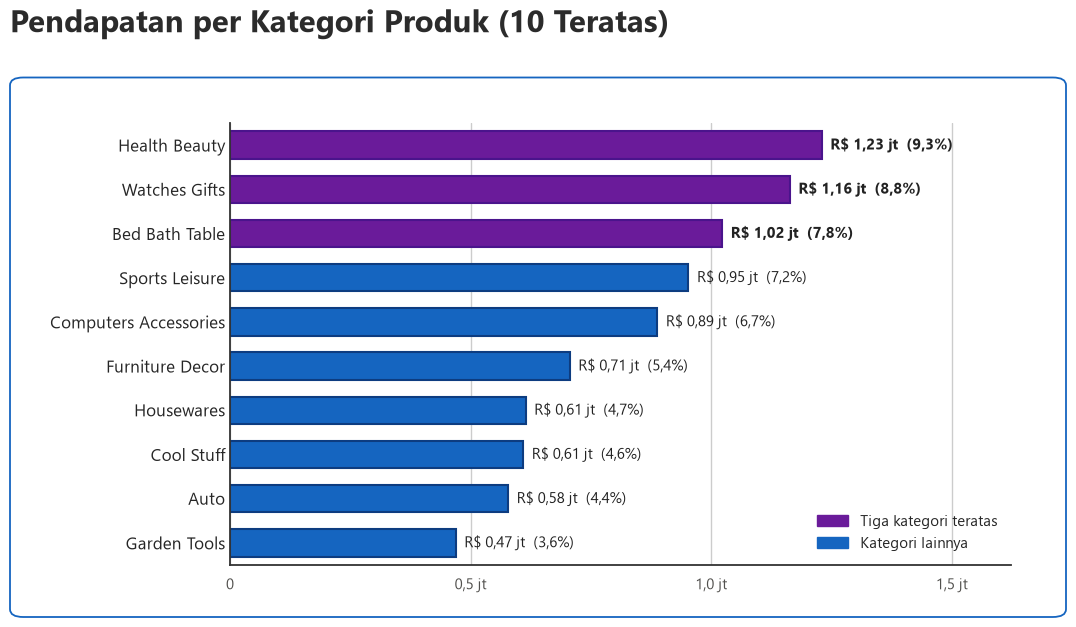

In [459]:
category_revenue_df = all_df.groupby(by="product_category_name_english").price.sum().sort_values(ascending=False).reset_index()
category_revenue_df["revenue_pct"] = category_revenue_df.price / category_revenue_df.price.sum() * 100
top10_df = category_revenue_df.head(10).copy()
top10_df["kategori"] = top10_df.product_category_name_english.str.replace("_", " ").str.title()

pct_top3 = top10_df.head(3).revenue_pct.sum()
pct_top10 = top10_df.revenue_pct.sum()
print(top10_df[["product_category_name_english", "price", "revenue_pct"]].round(2))
print("kontribusi top 3 :", round(pct_top3, 2), "%")
print("kontribusi top 10:", round(pct_top10, 2), "%")

fig, ax = buat_kartu("Pendapatan per Kategori Produk (10 Teratas)")
warna = [UNGU] * 3 + [BIRU] * 7
sns.barplot(x="price", y="kategori", hue="kategori", data=top10_df, palette=warna,
            legend=False, width=0.62, saturation=1, ax=ax)

# label nilai di ujung batang
for i, row in enumerate(top10_df.itertuples()):
    juta = f"{row.price / 1_000_000:.2f}".replace(".", ",")
    persen = f"{row.revenue_pct:.1f}".replace(".", ",")
    ax.text(row.price + 18000, i, f"R$ {juta} jt  ({persen}%)", va="center", fontsize=11,
            fontweight="bold" if i < 3 else "normal", color="#222222")

ax.set_xlim(0, top10_df.price.max() * 1.32)
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_xticks([0, 500000, 1000000, 1500000])
ax.set_xticklabels(["0", "0,5 jt", "1,0 jt", "1,5 jt"], fontsize=11, color=ABU)
ax.tick_params(axis="y", labelsize=12, length=0)

# garis tepi tiap batang (warna lebih gelap dari warna batang)
for batang, tepi in zip(ax.patches, ["#4A148C"] * 3 + ["#0D3C80"] * 7):
    batang.set_edgecolor(tepi)
    batang.set_linewidth(1.5)

# garis sumbu x dan y
sns.despine(top=True, right=True)
for sisi in ["left", "bottom"]:
    ax.spines[sisi].set_color(GARIS)
    ax.spines[sisi].set_linewidth(1.3)

ax.legend(handles=[Patch(color=UNGU, label="Tiga kategori teratas"), Patch(color=BIRU, label="Kategori lainnya")],
          loc="lower right", frameon=False, fontsize=11)
plt.show()

**Insight:**
- Sepuluh kategori teratas menyumbang 62,47% dari total pendapatan, dan tiga teratas saja menyumbang 25,92%. Pendapatan terkonsentrasi pada sebagian kecil kategori.
- Tiga kategori tertinggi adalah health_beauty (R$ 1.229.425,70 atau 9,33%), watches_gifts (R$ 1.163.121,02 atau 8,83%), dan bed_bath_table (R$ 1.022.541,17 atau 7,76%).
- Kategori peringkat 4 dan 5 adalah sports_leisure (7,23%) dan computers_accessories (6,74%). Kategori peringkat 10, garden_tools, berkontribusi 3,56%.

### Pertanyaan 2: Bagaimana tren pendapatan per bulan selama Januari 2017 sampai Agustus 2018, termasuk bulan puncak dan pertumbuhan persentasenya?

bulan puncak : Nov 2017
pendapatan   : 987648.07
pertumbuhan  : 52.36 %


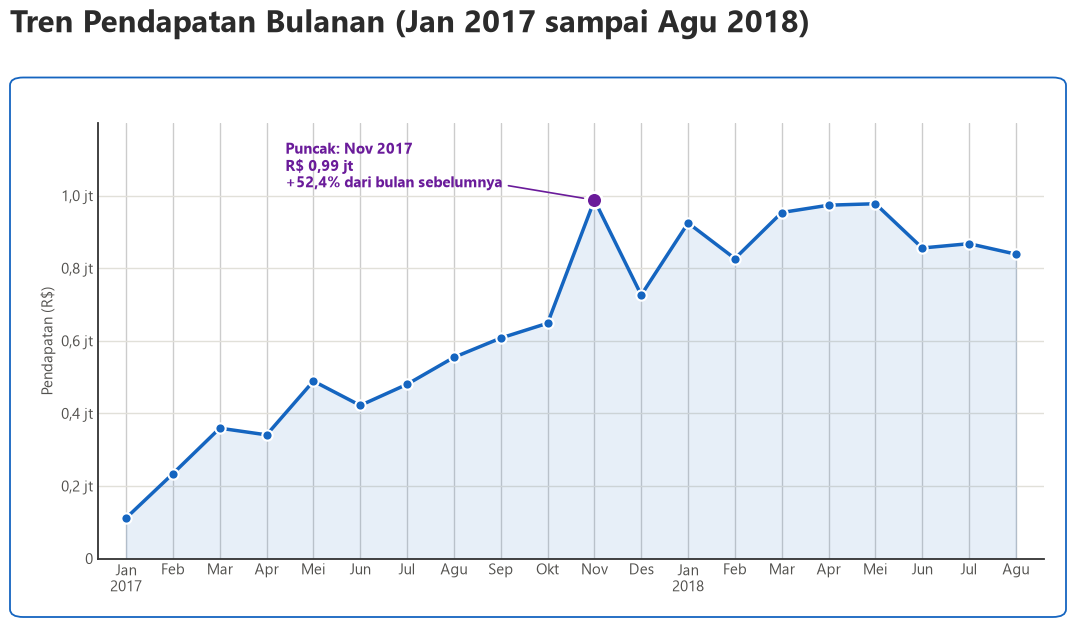

In [460]:
monthly_revenue_df = all_df.resample(rule="ME", on="order_purchase_timestamp").agg({"order_id": "nunique", "price": "sum"}).reset_index()
monthly_revenue_df.columns = ["month", "order_count", "revenue"]
monthly_revenue_df["growth_pct"] = monthly_revenue_df.revenue.pct_change() * 100

nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
# label sumbu x: nama bulan, dan tahun ditulis di bawah bulan Januari
monthly_revenue_df["label"] = monthly_revenue_df.month.apply(lambda x: nama_bulan[x.month - 1] + (f"\n{x.year}" if x.month == 1 else ""))
puncak = monthly_revenue_df.loc[monthly_revenue_df.revenue.idxmax()]
idx_puncak = monthly_revenue_df.revenue.idxmax()
print("bulan puncak :", nama_bulan[puncak.month.month - 1], puncak.month.year)
print("pendapatan   :", round(puncak.revenue, 2))
print("pertumbuhan  :", round(puncak.growth_pct, 2), "%")

x = range(len(monthly_revenue_df))
fig, ax = buat_kartu("Tren Pendapatan Bulanan (Jan 2017 sampai Agu 2018)", rect_ax=(0.10, 0.12, 0.86, 0.67))
ax.plot(x, monthly_revenue_df.revenue, color=BIRU, linewidth=2.5, zorder=2)
ax.fill_between(x, monthly_revenue_df.revenue, color=BIRU, alpha=0.10, zorder=1)
ax.scatter(x, monthly_revenue_df.revenue, s=55, color=BIRU, edgecolor="white", linewidth=1.5, zorder=3)
ax.scatter(idx_puncak, puncak.revenue, s=130, color=UNGU, edgecolor="white", linewidth=2, zorder=4)

teks_puncak = (f"Puncak: {nama_bulan[puncak.month.month - 1]} {puncak.month.year}\nR$ {puncak.revenue / 1_000_000:.2f} jt".replace(".", ",")
               + f"\n+{puncak.growth_pct:.1f}% dari bulan sebelumnya".replace(".", ","))
ax.annotate(teks_puncak, xy=(idx_puncak, puncak.revenue), xytext=(idx_puncak - 6.6, 1_080_000),
            fontsize=11, fontweight="bold", color=UNGU, va="center",
            arrowprops=dict(arrowstyle="-", color=UNGU, linewidth=1.2, shrinkA=2, shrinkB=8))

ax.set_ylim(0, 1_200_000)
ax.set_yticks([0, 200000, 400000, 600000, 800000, 1000000])
ax.set_yticklabels(["0", "0,2 jt", "0,4 jt", "0,6 jt", "0,8 jt", "1,0 jt"], fontsize=11, color=ABU)
ax.set_xticks(list(x))
ax.set_xticklabels(monthly_revenue_df.label, fontsize=10.5, color=ABU)
ax.set_xlim(-0.6, len(monthly_revenue_df) - 0.4)
ax.set_xlabel(None); ax.set_ylabel("Pendapatan (R$)", fontsize=11, color=ABU)
ax.tick_params(length=0)
ax.grid(axis="y", color="#E1E0D9", linewidth=1)
ax.set_axisbelow(True)
sns.despine(top=True, right=True)
for sisi in ["left", "bottom"]:
    ax.spines[sisi].set_color(GARIS); ax.spines[sisi].set_linewidth(1.3)
plt.show()

**Insight:**
- Pendapatan bulanan naik dari R$ 111.609,71 pada Januari 2017 menjadi R$ 838.576,64 pada Agustus 2018.
- Puncak terjadi pada November 2017 sebesar R$ 987.648,07 dari 7.288 pesanan, naik 52,36% dibanding Oktober 2017.
- Setelah puncak, Desember 2017 turun 26,49%, lalu Januari 2018 naik lagi 27,36%.
- Sepanjang 2018 pendapatan relatif stabil di kisaran R$ 826.437,13 sampai R$ 977.544,69 per bulan. Total Januari sampai Agustus 2018 (R$ 7.217.172,24) sudah melampaui total Januari sampai Desember 2017 (R$ 5.959.433,91).

### Pertanyaan 3: Negara bagian mana yang termasuk 5 teratas dengan persentase pesanan terlambat tertinggi selama Januari 2017 sampai Agustus 2018?

rata-rata nasional: 6.79 %
   customer_state  order_count  late_count  late_pct
1              AL          396          85     21.46
9              MA          713         125     17.53
24             SE          332          51     15.36
16             PI          475          66     13.89
5              CE         1273         176     13.83
4              BA         3253         396     12.17
18             RJ        12310        1495     12.14
13             PA          942         106     11.25
7              ES         1992         214     10.74
14             PB          516          54     10.47


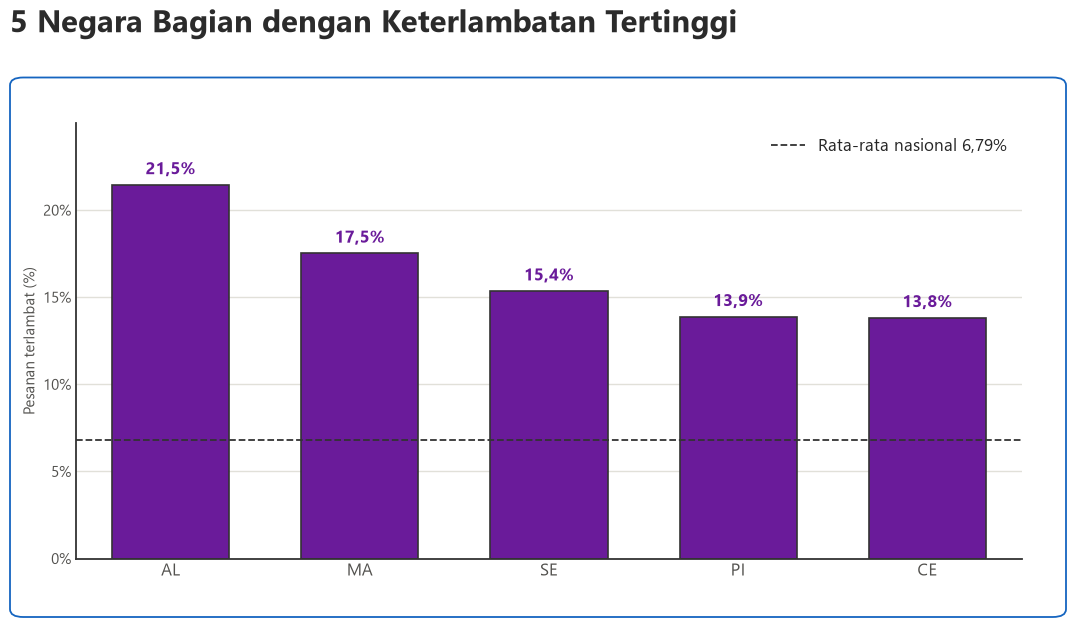

In [461]:
order_df = all_df.drop_duplicates(subset="order_id")
state_delay_df = order_df.groupby(by="customer_state").agg({"order_id": "nunique", "is_late": "sum"}).reset_index()
state_delay_df.columns = ["customer_state", "order_count", "late_count"]
state_delay_df["late_pct"] = round(state_delay_df.late_count / state_delay_df.order_count * 100, 2)
rata_nasional = state_delay_df.late_count.sum() / state_delay_df.order_count.sum() * 100

# hanya state dengan minimal 100 pesanan agar persentase tidak bias oleh sampel kecil
top_state_df = state_delay_df[state_delay_df.order_count >= 100].sort_values(by="late_pct", ascending=False).head(10)
top5_df = top_state_df.head(5)
print("rata-rata nasional:", round(rata_nasional, 2), "%")
print(top_state_df)

warna = [UNGU] * 5
fig, ax = buat_kartu("5 Negara Bagian dengan Keterlambatan Tertinggi", rect_ax=(0.08, 0.12, 0.86, 0.67))
sns.barplot(x="customer_state", y="late_pct", data=top5_df, palette=warna, hue="customer_state", legend=False, saturation=1, edgecolor=GARIS, linewidth=1.2, width=0.62, ax=ax)
for i, nilai in enumerate(top5_df.late_pct):
    ax.text(i, nilai + 0.4, f"{nilai:.1f}%".replace(".", ","), ha="center", va="bottom", fontsize=12, fontweight="bold", color=UNGU)
ax.axhline(rata_nasional, color=GARIS, linestyle="--", linewidth=1.3, zorder=4, label=f"Rata-rata nasional {rata_nasional:.2f}%".replace(".", ","))
ax.legend(loc="upper right", frameon=False, fontsize=12)
ax.set_ylim(0, 25); ax.set_yticks([0, 5, 10, 15, 20])
ax.set_yticklabels(["0%", "5%", "10%", "15%", "20%"], fontsize=11, color=ABU)
ax.tick_params(axis="x", labelsize=12, labelcolor=ABU)
ax.set_xlabel(None); ax.set_ylabel("Pesanan terlambat (%)", fontsize=11, color=ABU)
ax.tick_params(length=0)
ax.grid(axis="y", color="#E1E0D9", linewidth=1); ax.set_axisbelow(True)
sns.despine(top=True, right=True)
for sisi in ["left", "bottom"]:
    ax.spines[sisi].set_color(GARIS); ax.spines[sisi].set_linewidth(1.3)
plt.show()

In [462]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.


(27, 13) 0
   sigla  order_count  late_pct
1     AL          396     21.46
8     MA          713     17.53
23    SE          332     15.36
15    PI          475     13.89
5     CE         1273     13.83


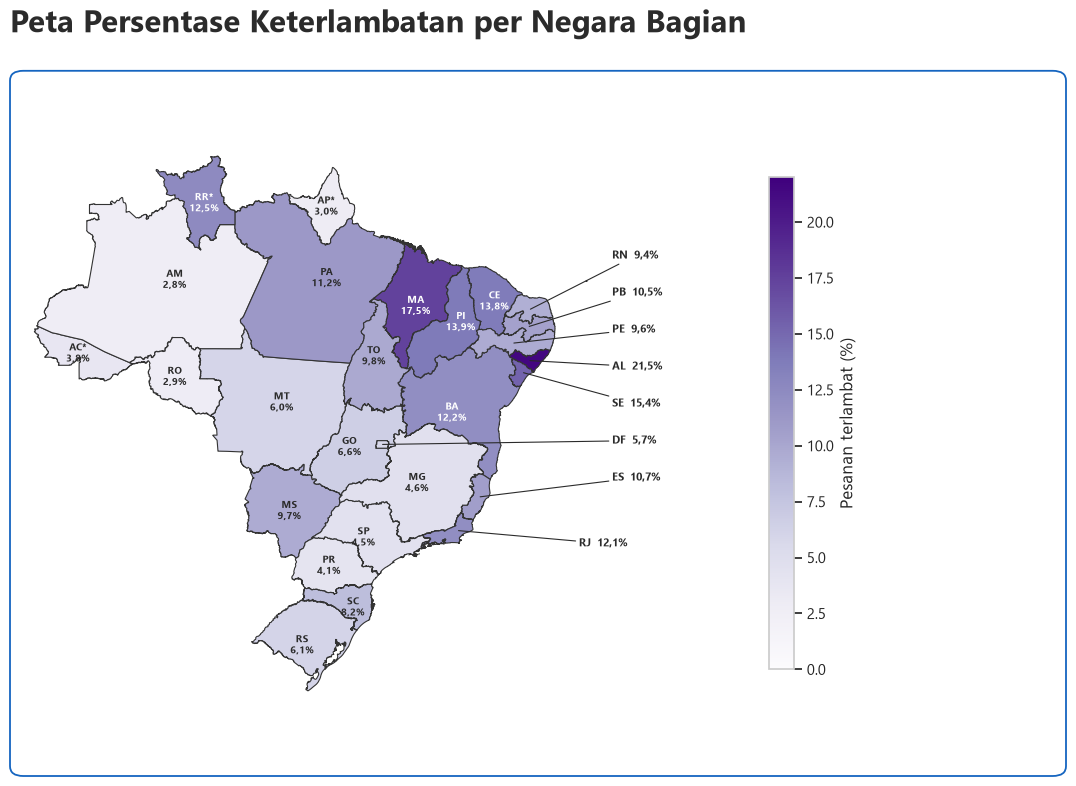

In [463]:
url_peta = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson"
brasil_gdf = gpd.read_file(url_peta)

brasil_gdf = brasil_gdf.merge(state_delay_df, how="left", left_on="sigla", right_on="customer_state")
print(brasil_gdf.shape, brasil_gdf.late_pct.isna().sum())
print(brasil_gdf[["sigla", "order_count", "late_pct"]].sort_values(by="late_pct", ascending=False).head(5))

fig, ax = buat_kartu("Peta Persentase Keterlambatan per Negara Bagian", ukuran=(11, 8.2), area=(0.02, 0.03, 0.96, 0.86), rect_ax=(0.03, 0.06, 0.80, 0.80))
brasil_gdf.plot(column="late_pct", cmap="Purples", vmin=0, vmax=22, edgecolor="#333333", linewidth=0.8, ax=ax,
                legend=True, legend_kwds={"shrink": 0.75, "label": "Pesanan terlambat (%)"})

# label: kode negara bagian dan persentase (tanda * = kurang dari 100 pesanan)
# negara bagian kecil di pesisir timur diberi label di luar wilayah dengan garis penghubung
label_luar = {"RN": (-30.5, -2.0), "PB": (-30.5, -4.7), "PE": (-30.5, -7.4), "AL": (-30.5, -10.1), "SE": (-30.5, -12.8),
              "DF": (-30.5, -15.5), "ES": (-30.5, -18.2), "RJ": (-33.0, -23.0)}
titik = brasil_gdf.geometry.representative_point()
for sigla, pct, n, p in zip(brasil_gdf.sigla, brasil_gdf.late_pct, brasil_gdf.order_count, titik):
    teks = f"{sigla}{'*' if n < 100 else ''}  {pct:.1f}%".replace(".", ",") if sigla in label_luar else f"{sigla}{'*' if n < 100 else ''}\n{pct:.1f}%".replace(".", ",")
    if sigla in label_luar:
        ax.annotate(teks, xy=(p.x, p.y), xytext=label_luar[sigla], ha="left" if label_luar[sigla][0] > -40 else "right", va="center", fontsize=8,
                    fontweight="bold", color="#2B2B2B", arrowprops=dict(arrowstyle="-", color="#2B2B2B", linewidth=0.8, shrinkA=0, shrinkB=0))
    else:
        ax.text(p.x, p.y, teks, ha="center", va="center", fontsize=7.5, fontweight="bold", color="white" if pct > 12 else "#2B2B2B")
ax.set_xlabel(None); ax.set_ylabel(None)
ax.set_xlim(-75, -22)
ax.set_xticks([]); ax.set_yticks([])
for sisi in ["top", "right", "left", "bottom"]:
    ax.spines[sisi].set_visible(False)
plt.show()

**Insight:**
- Lima negara bagian dengan persentase keterlambatan tertinggi adalah AL (21,46%), MA (17,53%), SE (15,36%), PI (13,89%), dan CE (13,83%). Semuanya lebih dari dua kali rata-rata nasional (6,79%).
- Kelima negara bagian itu terletak di wilayah timur laut Brasil, sehingga dugaan pada tahap EDA terbukti pada peta. Pada peta, warna paling gelap memang mengelompok di sana.
- Peringkat 6 sampai 10 adalah BA (12,17%), RJ (12,14%), PA (11,25%), ES (10,74%), dan PB (10,47%). Karena RJ dan ES berada di tenggara, masalah keterlambatan tidak hanya terjadi di timur laut.
- RJ memiliki 12.310 pesanan dengan 1.495 di antaranya terlambat, jumlah terlambat terbesar di antara negara bagian dengan persentase tinggi.

### Pertanyaan 4: Berapa penurunan rata-rata skor ulasan pada pesanan yang terlambat 1 sampai 3 hari, 4 sampai 7 hari, atau lebih dari 7 hari dibandingkan pesanan tepat waktu selama Januari 2017 sampai Agustus 2018?

         delay_status  avg_review_score  review_count  low_score_pct  score_drop  score_drop_pct
0         Tepat waktu              4.29         89163           9.24        0.00            0.00
1  Terlambat 1-3 hari              3.29          1851          32.14        1.00           23.32
2  Terlambat 4-7 hari              2.10          1748          67.62        2.19           50.96
3  Terlambat > 7 hari              1.70          2779          79.27        2.60           60.47


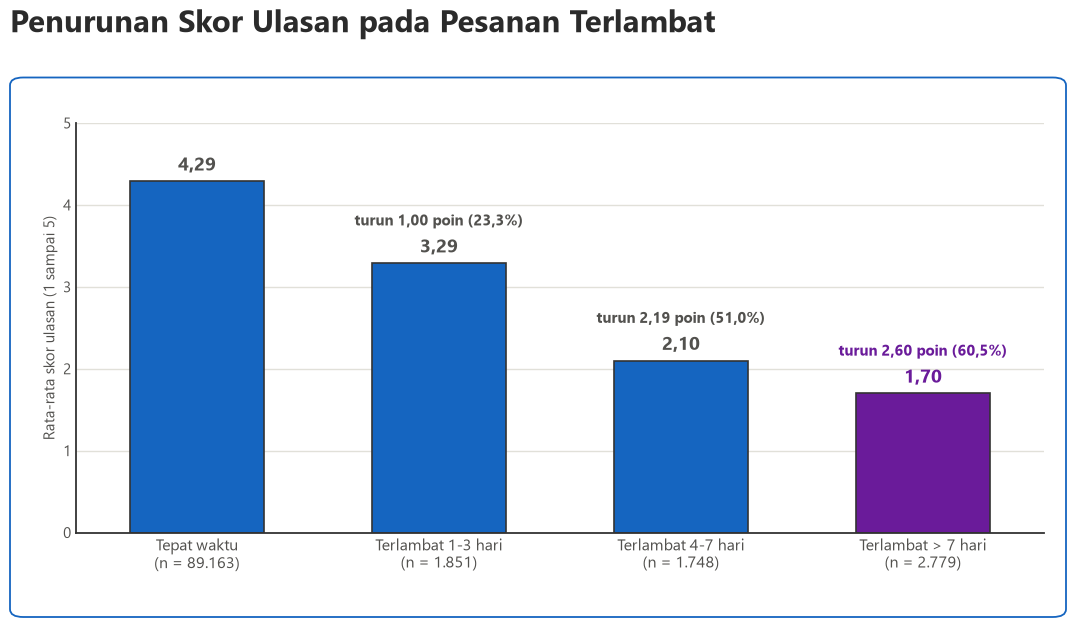

In [464]:
review_df = order_df.dropna(subset=["review_score"]).copy()
review_df["low_score"] = review_df.review_score.apply(lambda x: 1 if x <= 2 else 0)
urutan = ["Tepat waktu", "Terlambat 1-3 hari", "Terlambat 4-7 hari", "Terlambat > 7 hari"]
delay_review_df = review_df.groupby(by="delay_status").agg({"review_score": ["mean", "count"], "low_score": "mean"}).reindex(urutan)
delay_review_df.columns = ["avg_review_score", "review_count", "low_score_pct"]
delay_review_df["low_score_pct"] = delay_review_df.low_score_pct * 100

# penurunan skor dibanding pesanan tepat waktu (dihitung dari nilai asli sebelum dibulatkan)
skor_tepat_waktu = delay_review_df.loc["Tepat waktu", "avg_review_score"]
delay_review_df["score_drop"] = skor_tepat_waktu - delay_review_df.avg_review_score
delay_review_df["score_drop_pct"] = delay_review_df.score_drop / skor_tepat_waktu * 100
delay_review_df = delay_review_df.round(2).reset_index()
print(delay_review_df)

warna = [BIRU, BIRU, BIRU, UNGU]
fig, ax = buat_kartu("Penurunan Skor Ulasan pada Pesanan Terlambat", rect_ax=(0.08, 0.16, 0.88, 0.63))
sns.barplot(x="delay_status", y="avg_review_score", data=delay_review_df, palette=warna, hue="delay_status", legend=False, saturation=1, edgecolor=GARIS, linewidth=1.2, width=0.55, ax=ax)
for i, baris in delay_review_df.iterrows():
    warna_teks = UNGU if i == 3 else ABU
    ax.text(i, baris.avg_review_score + 0.08, f"{baris.avg_review_score:.2f}".replace(".", ","), ha="center", va="bottom", fontsize=14, fontweight="bold", color=warna_teks)
    if i > 0:
        ax.text(i, baris.avg_review_score + 0.42, f"turun {baris.score_drop:.2f} poin ({baris.score_drop_pct:.1f}%)".replace(".", ","), ha="center", va="bottom", fontsize=11, fontweight="bold", color=warna_teks)
ax.set_xticks(range(4))
ax.set_xticklabels([f"{s}\n(n = {n:,})".replace(",", ".") for s, n in zip(delay_review_df.delay_status, delay_review_df.review_count)], fontsize=11.5, color=ABU)
ax.set_ylim(0, 5); ax.set_yticks([0, 1, 2, 3, 4, 5])
ax.set_yticklabels(["0", "1", "2", "3", "4", "5"], fontsize=11, color=ABU)
ax.set_xlabel(None); ax.set_ylabel("Rata-rata skor ulasan (1 sampai 5)", fontsize=11, color=ABU)
ax.tick_params(length=0)
ax.grid(axis="y", color="#E1E0D9", linewidth=1); ax.set_axisbelow(True)
sns.despine(top=True, right=True)
for sisi in ["left", "bottom"]:
    ax.spines[sisi].set_color(GARIS); ax.spines[sisi].set_linewidth(1.3)
plt.show()

**Insight:**
- Rata-rata skor ulasan turun tajam seiring lamanya keterlambatan: 4,29 untuk pesanan tepat waktu, 3,29 untuk terlambat 1 sampai 3 hari, 2,10 untuk 4 sampai 7 hari, dan 1,70 untuk lebih dari 7 hari.
- Penurunan dibanding pesanan tepat waktu adalah 1,00 poin (23,32%) pada keterlambatan 1 sampai 3 hari, 2,19 poin (50,96%) pada 4 sampai 7 hari, dan 2,60 poin (60,47%) pada lebih dari 7 hari.
- Persentase ulasan berskor rendah (1 atau 2) naik dari 9,24% pada pesanan tepat waktu menjadi 32,14%, 67,62%, dan 79,27% pada kelompok terlambat yang makin lama.
- Keterlambatan 1 sampai 3 hari saja sudah menurunkan skor hampir seperempat, sehingga pelanggan sensitif bahkan terhadap keterlambatan singkat.

### Pertanyaan 5: Segmen pelanggan RFM (recency, frequency, monetary) mana yang menyumbang pendapatan terbesar pada pembelian Januari 2017 sampai Agustus 2018?

                 segment  customer_count     revenue  avg_monetary  avg_recency  customer_pct  revenue_pct
0  Aktif Bernilai Tinggi           23613  5556530.42        235.32       114.60         25.37        42.17
1  Pasif Bernilai Tinggi           22934  5421773.94        236.41       364.62         24.64        41.15
2  Aktif Bernilai Rendah           23061  1086969.88         47.13       114.01         24.78         8.25
3  Pasif Bernilai Rendah           23472  1111331.91         47.35       365.05         25.22         8.43
Bernilai Tinggi -> pelanggan: 50.01 % | pendapatan: 83.32 %


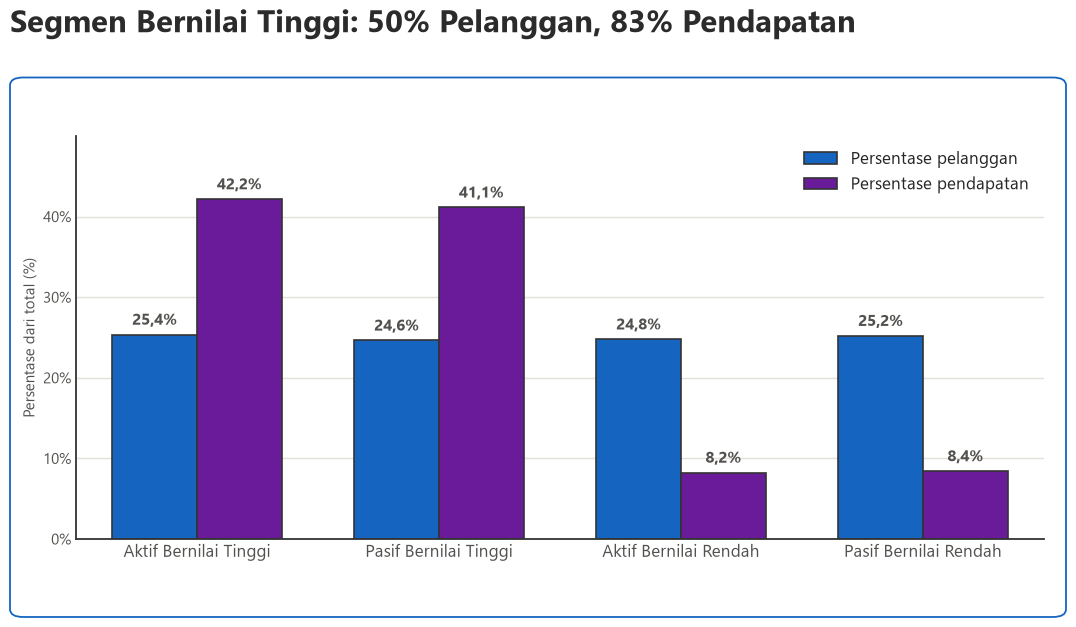

In [465]:
customer_df = all_df.drop_duplicates(subset="customer_unique_id")
rfm_segment_df = customer_df.groupby(by="segment").agg({"customer_unique_id": "nunique", "monetary": ["sum", "mean"], "recency": "mean"})
rfm_segment_df.columns = ["customer_count", "revenue", "avg_monetary", "avg_recency"]
rfm_segment_df["customer_pct"] = round(rfm_segment_df.customer_count / rfm_segment_df.customer_count.sum() * 100, 2)
rfm_segment_df["revenue_pct"] = round(rfm_segment_df.revenue / rfm_segment_df.revenue.sum() * 100, 2)
urutan = ["Aktif Bernilai Tinggi", "Pasif Bernilai Tinggi", "Aktif Bernilai Rendah", "Pasif Bernilai Rendah"]
rfm_segment_df = rfm_segment_df.reindex(urutan).round(2).reset_index()
print(rfm_segment_df)
tinggi_df = rfm_segment_df[rfm_segment_df.segment.str.contains("Tinggi")]
print("Bernilai Tinggi -> pelanggan:", round(tinggi_df.customer_pct.sum(), 2), "% | pendapatan:", round(tinggi_df.revenue_pct.sum(), 2), "%")

plot_df = rfm_segment_df.melt(id_vars="segment", value_vars=["customer_pct", "revenue_pct"], var_name="ukuran", value_name="persen")
plot_df["ukuran"] = plot_df.ukuran.map({"customer_pct": "Persentase pelanggan", "revenue_pct": "Persentase pendapatan"})
fig, ax = buat_kartu("Segmen Bernilai Tinggi: 50% Pelanggan, 83% Pendapatan", rect_ax=(0.08, 0.15, 0.88, 0.62))
sns.barplot(x="segment", y="persen", hue="ukuran", data=plot_df, order=urutan, palette=[BIRU, UNGU], saturation=1, edgecolor=GARIS, linewidth=1.2, width=0.7, ax=ax)
for wadah in ax.containers:
    for batang in wadah:
        nilai = batang.get_height()
        ax.text(batang.get_x() + batang.get_width() / 2, nilai + 0.8, f"{nilai:.1f}%".replace(".", ","), ha="center", va="bottom", fontsize=11.5, fontweight="bold", color=ABU)
ax.set_ylim(0, 50); ax.set_yticks([0, 10, 20, 30, 40])
ax.set_yticklabels(["0%", "10%", "20%", "30%", "40%"], fontsize=11, color=ABU)
ax.tick_params(axis="x", labelsize=12, labelcolor=ABU)
ax.set_xlabel(None); ax.set_ylabel("Persentase dari total (%)", fontsize=11, color=ABU)
ax.tick_params(length=0)
ax.legend(loc="upper right", frameon=False, fontsize=12)
ax.grid(axis="y", color="#E1E0D9", linewidth=1); ax.set_axisbelow(True)
sns.despine(top=True, right=True)
for sisi in ["left", "bottom"]:
    ax.spines[sisi].set_color(GARIS); ax.spines[sisi].set_linewidth(1.3)
plt.show()

**Insight:**
- Segmen penyumbang pendapatan terbesar adalah Aktif Bernilai Tinggi: 23.613 pelanggan (25,37%) menyumbang R$ 5.556.530,42 atau 42,17% dari total pendapatan.
- Selisihnya tipis dengan Pasif Bernilai Tinggi (41,15%, R$ 5.421.773,94). Peringkat keduanya bergantung pada batas recency yang dipakai, jadi temuan yang lebih stabil adalah bahwa kedua segmen Bernilai Tinggi sama-sama dominan.
- Dua segmen Bernilai Tinggi hanya 50,01% dari pelanggan, tetapi menghasilkan 83,32% pendapatan. Rata-rata belanjanya sekitar R$ 235 sampai R$ 236, dibanding sekitar R$ 47 pada segmen Bernilai Rendah.
- Keempat segmen hampir sama besar (24,64% sampai 25,37% dari pelanggan), jadi perbedaan pendapatan berasal dari nilai belanja, bukan jumlah pelanggan.

## Analisis Lanjutan (Opsional)

#### RFM Analysis

                 segment  customer_count     revenue  avg_monetary  avg_recency  customer_pct  revenue_pct
0  Aktif Bernilai Tinggi           23613  5556530.42        235.32       114.60         25.37        42.17
1  Pasif Bernilai Tinggi           22934  5421773.94        236.41       364.62         24.64        41.15
2  Aktif Bernilai Rendah           23061  1086969.88         47.13       114.01         24.78         8.25
3  Pasif Bernilai Rendah           23472  1111331.91         47.35       365.05         25.22         8.43
Bernilai Tinggi -> pelanggan: 50.01 % | pendapatan: 83.32 %


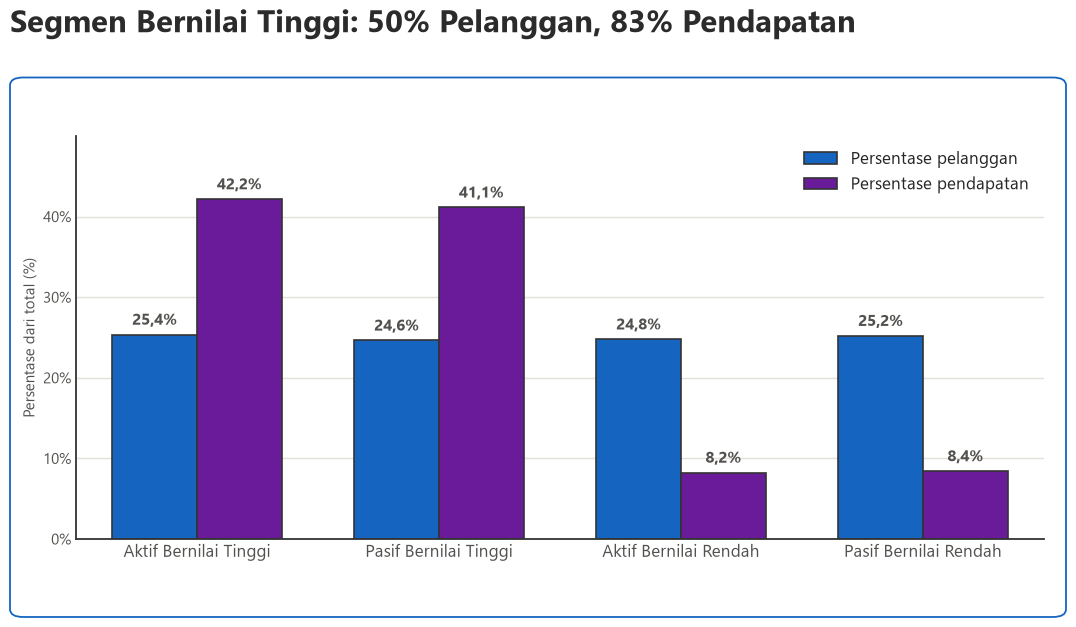

In [466]:
customer_df = all_df.drop_duplicates(subset="customer_unique_id")
rfm_segment_df = customer_df.groupby(by="segment").agg({"customer_unique_id": "nunique", "monetary": ["sum", "mean"], "recency": "mean"})
rfm_segment_df.columns = ["customer_count", "revenue", "avg_monetary", "avg_recency"]
rfm_segment_df["customer_pct"] = round(rfm_segment_df.customer_count / rfm_segment_df.customer_count.sum() * 100, 2)
rfm_segment_df["revenue_pct"] = round(rfm_segment_df.revenue / rfm_segment_df.revenue.sum() * 100, 2)
urutan = ["Aktif Bernilai Tinggi", "Pasif Bernilai Tinggi", "Aktif Bernilai Rendah", "Pasif Bernilai Rendah"]
rfm_segment_df = rfm_segment_df.reindex(urutan).round(2).reset_index()
print(rfm_segment_df)
tinggi_df = rfm_segment_df[rfm_segment_df.segment.str.contains("Tinggi")]
print("Bernilai Tinggi -> pelanggan:", round(tinggi_df.customer_pct.sum(), 2), "% | pendapatan:", round(tinggi_df.revenue_pct.sum(), 2), "%")

plot_df = rfm_segment_df.melt(id_vars="segment", value_vars=["customer_pct", "revenue_pct"], var_name="ukuran", value_name="persen")
plot_df["ukuran"] = plot_df.ukuran.map({"customer_pct": "Persentase pelanggan", "revenue_pct": "Persentase pendapatan"})
fig, ax = buat_kartu("Segmen Bernilai Tinggi: 50% Pelanggan, 83% Pendapatan", rect_ax=(0.08, 0.15, 0.88, 0.62))
sns.barplot(x="segment", y="persen", hue="ukuran", data=plot_df, order=urutan, palette=[BIRU, UNGU], saturation=1, edgecolor=GARIS, linewidth=1.2, width=0.7, ax=ax)
for wadah in ax.containers:
    for batang in wadah:
        nilai = batang.get_height()
        ax.text(batang.get_x() + batang.get_width() / 2, nilai + 0.8, f"{nilai:.1f}%".replace(".", ","), ha="center", va="bottom", fontsize=11.5, fontweight="bold", color=ABU)
ax.set_ylim(0, 50); ax.set_yticks([0, 10, 20, 30, 40])
ax.set_yticklabels(["0%", "10%", "20%", "30%", "40%"], fontsize=11, color=ABU)
ax.tick_params(axis="x", labelsize=12, labelcolor=ABU)
ax.set_xlabel(None); ax.set_ylabel("Persentase dari total (%)", fontsize=11, color=ABU)
ax.tick_params(length=0)
ax.legend(loc="upper right", frameon=False, fontsize=12)
ax.grid(axis="y", color="#E1E0D9", linewidth=1); ax.set_axisbelow(True)
sns.despine(top=True, right=True)
for sisi in ["left", "bottom"]:
    ax.spines[sisi].set_color(GARIS); ax.spines[sisi].set_linewidth(1.3)
plt.show()

#### Geospatial Analysis

(27, 13) 0
   sigla  order_count  late_pct
1     AL          396     21.46
8     MA          713     17.53
23    SE          332     15.36
15    PI          475     13.89
5     CE         1273     13.83


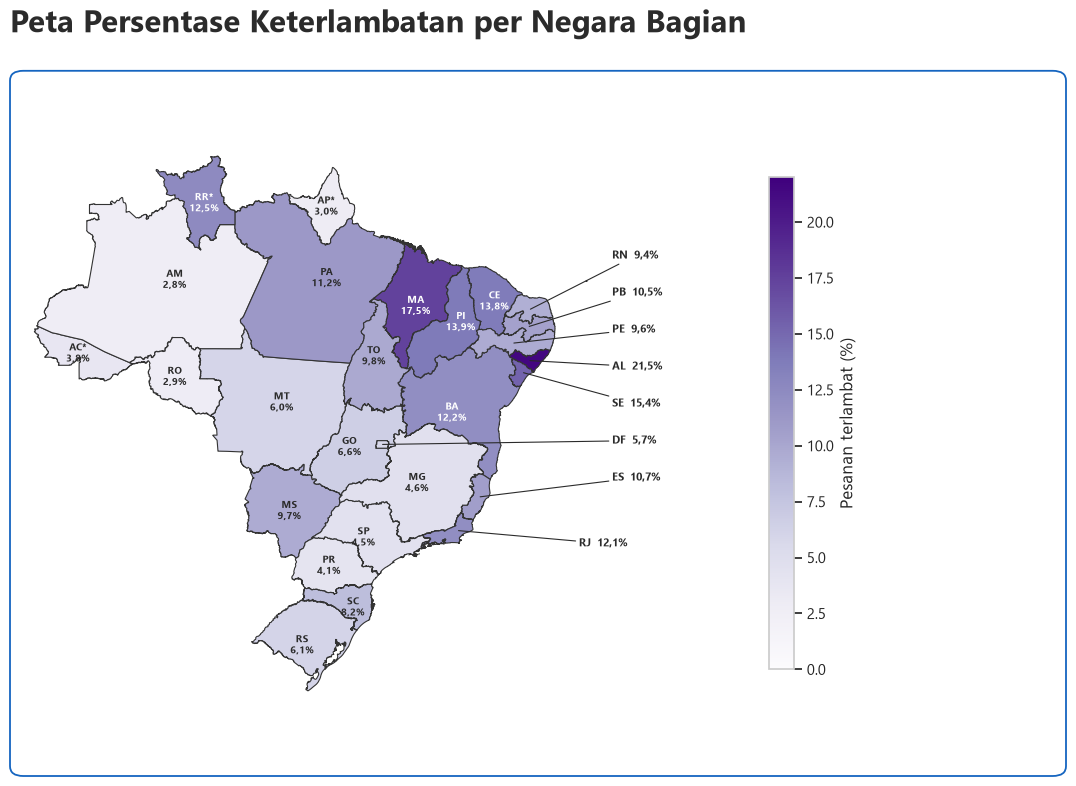

In [467]:
url_peta = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson"
brasil_gdf = gpd.read_file(url_peta)

brasil_gdf = brasil_gdf.merge(state_delay_df, how="left", left_on="sigla", right_on="customer_state")
print(brasil_gdf.shape, brasil_gdf.late_pct.isna().sum())
print(brasil_gdf[["sigla", "order_count", "late_pct"]].sort_values(by="late_pct", ascending=False).head(5))

fig, ax = buat_kartu("Peta Persentase Keterlambatan per Negara Bagian", ukuran=(11, 8.2), area=(0.02, 0.03, 0.96, 0.86), rect_ax=(0.03, 0.06, 0.80, 0.80))
brasil_gdf.plot(column="late_pct", cmap="Purples", vmin=0, vmax=22, edgecolor="#333333", linewidth=0.8, ax=ax,
                legend=True, legend_kwds={"shrink": 0.75, "label": "Pesanan terlambat (%)"})

# label: kode negara bagian dan persentase (tanda * = kurang dari 100 pesanan)
# negara bagian kecil di pesisir timur diberi label di luar wilayah dengan garis penghubung
label_luar = {"RN": (-30.5, -2.0), "PB": (-30.5, -4.7), "PE": (-30.5, -7.4), "AL": (-30.5, -10.1), "SE": (-30.5, -12.8),
              "DF": (-30.5, -15.5), "ES": (-30.5, -18.2), "RJ": (-33.0, -23.0)}
titik = brasil_gdf.geometry.representative_point()
for sigla, pct, n, p in zip(brasil_gdf.sigla, brasil_gdf.late_pct, brasil_gdf.order_count, titik):
    teks = f"{sigla}{'*' if n < 100 else ''}  {pct:.1f}%".replace(".", ",") if sigla in label_luar else f"{sigla}{'*' if n < 100 else ''}\n{pct:.1f}%".replace(".", ",")
    if sigla in label_luar:
        ax.annotate(teks, xy=(p.x, p.y), xytext=label_luar[sigla], ha="left" if label_luar[sigla][0] > -40 else "right", va="center", fontsize=8,
                    fontweight="bold", color="#2B2B2B", arrowprops=dict(arrowstyle="-", color="#2B2B2B", linewidth=0.8, shrinkA=0, shrinkB=0))
    else:
        ax.text(p.x, p.y, teks, ha="center", va="center", fontsize=7.5, fontweight="bold", color="white" if pct > 12 else "#2B2B2B")
ax.set_xlabel(None); ax.set_ylabel(None)
ax.set_xlim(-75, -22)
ax.set_xticks([]); ax.set_yticks([])
for sisi in ["top", "right", "left", "bottom"]:
    ax.spines[sisi].set_visible(False)
plt.show()

#### Bining

         delay_status  avg_review_score  review_count  low_score_pct  score_drop  score_drop_pct
0         Tepat waktu              4.29         89163           9.24        0.00            0.00
1  Terlambat 1-3 hari              3.29          1851          32.14        1.00           23.32
2  Terlambat 4-7 hari              2.10          1748          67.62        2.19           50.96
3  Terlambat > 7 hari              1.70          2779          79.27        2.60           60.47


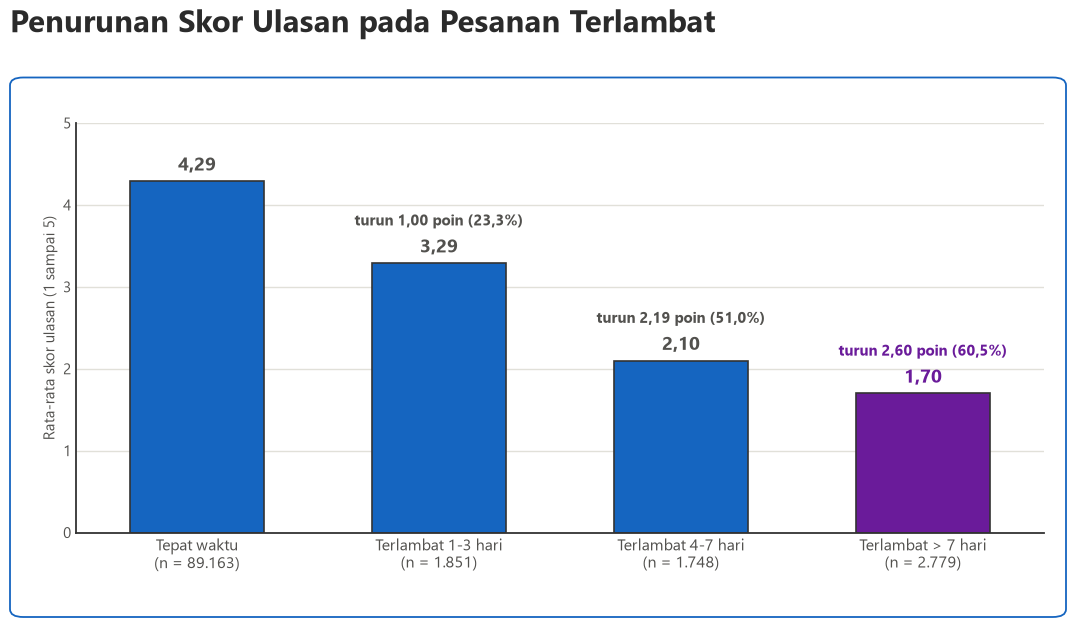

In [468]:
review_df = order_df.dropna(subset=["review_score"]).copy()
review_df["low_score"] = review_df.review_score.apply(lambda x: 1 if x <= 2 else 0)
urutan = ["Tepat waktu", "Terlambat 1-3 hari", "Terlambat 4-7 hari", "Terlambat > 7 hari"]
delay_review_df = review_df.groupby(by="delay_status").agg({"review_score": ["mean", "count"], "low_score": "mean"}).reindex(urutan)
delay_review_df.columns = ["avg_review_score", "review_count", "low_score_pct"]
delay_review_df["low_score_pct"] = delay_review_df.low_score_pct * 100

# penurunan skor dibanding pesanan tepat waktu (dihitung dari nilai asli sebelum dibulatkan)
skor_tepat_waktu = delay_review_df.loc["Tepat waktu", "avg_review_score"]
delay_review_df["score_drop"] = skor_tepat_waktu - delay_review_df.avg_review_score
delay_review_df["score_drop_pct"] = delay_review_df.score_drop / skor_tepat_waktu * 100
delay_review_df = delay_review_df.round(2).reset_index()
print(delay_review_df)

warna = [BIRU, BIRU, BIRU, UNGU]
fig, ax = buat_kartu("Penurunan Skor Ulasan pada Pesanan Terlambat", rect_ax=(0.08, 0.16, 0.88, 0.63))
sns.barplot(x="delay_status", y="avg_review_score", data=delay_review_df, palette=warna, hue="delay_status", legend=False, saturation=1, edgecolor=GARIS, linewidth=1.2, width=0.55, ax=ax)
for i, baris in delay_review_df.iterrows():
    warna_teks = UNGU if i == 3 else ABU
    ax.text(i, baris.avg_review_score + 0.08, f"{baris.avg_review_score:.2f}".replace(".", ","), ha="center", va="bottom", fontsize=14, fontweight="bold", color=warna_teks)
    if i > 0:
        ax.text(i, baris.avg_review_score + 0.42, f"turun {baris.score_drop:.2f} poin ({baris.score_drop_pct:.1f}%)".replace(".", ","), ha="center", va="bottom", fontsize=11, fontweight="bold", color=warna_teks)
ax.set_xticks(range(4))
ax.set_xticklabels([f"{s}\n(n = {n:,})".replace(",", ".") for s, n in zip(delay_review_df.delay_status, delay_review_df.review_count)], fontsize=11.5, color=ABU)
ax.set_ylim(0, 5); ax.set_yticks([0, 1, 2, 3, 4, 5])
ax.set_yticklabels(["0", "1", "2", "3", "4", "5"], fontsize=11, color=ABU)
ax.set_xlabel(None); ax.set_ylabel("Rata-rata skor ulasan (1 sampai 5)", fontsize=11, color=ABU)
ax.tick_params(length=0)
ax.grid(axis="y", color="#E1E0D9", linewidth=1); ax.set_axisbelow(True)
sns.despine(top=True, right=True)
for sisi in ["left", "bottom"]:
    ax.spines[sisi].set_color(GARIS); ax.spines[sisi].set_linewidth(1.3)
plt.show()

#### Insight

**Insight:**
- **RFM:** pelanggan Bernilai Tinggi hanya 50,01% dari pelanggan, tetapi menyumbang 83,32% pendapatan. Dengan rata-rata belanja sekitar R$ 235 sampai R$ 236 dibanding sekitar R$ 47 pada pelanggan Bernilai Rendah, strategi pemasaran sebaiknya dibedakan per segmen.
- **Geospasial:** lima negara bagian dengan keterlambatan tertinggi (AL, MA, SE, PI, CE) semuanya berada di timur laut Brasil, dan persentasenya lebih dari dua kali rata-rata nasional (6,79%). Pola ini menunjukkan keterlambatan terkonsentrasi di wilayah tertentu, bukan merata.
- **Binning:** pengelompokan keterlambatan menunjukkan skor ulasan turun 1,00 poin pada keterlambatan 1 sampai 3 hari, 2,19 poin pada 4 sampai 7 hari, dan 2,60 poin pada lebih dari 7 hari dibanding pesanan tepat waktu. Makin lama keterlambatan, makin besar penurunan skor.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pendapatan terkonsentrasi pada sebagian kecil kategori. Dari total pendapatan R$ 13.176.606,15 yang tersebar di 74 kategori, sepuluh kategori teratas menyumbang 62,47%. Tiga kategori tertinggi adalah health_beauty (9,33%), watches_gifts (8,83%), dan bed_bath_table (7,76%), dengan kontribusi gabungan 25,92%. Jumlah item terjual tidak selalu sejalan dengan pendapatan. bed_bath_table memiliki item terbanyak (10.941) tetapi berada di peringkat 3, sedangkan watches_gifts hanya terjual 5.852 item namun berada di peringkat 2 karena harga per itemnya lebih tinggi.

- **Conclusion pertanyaan 2:** Pendapatan bulanan tumbuh dari R$ 111.609,71 pada Januari 2017 menjadi R$ 838.576,64 pada Agustus 2018, dengan puncak pada November 2017 sebesar R$ 987.648,07 dari 7.288 pesanan (naik 52,36% dari Oktober 2017). Setelah puncak, pendapatan turun 26,49% pada Desember 2017, lalu pulih pada Januari 2018 (naik 27,36%). Sepanjang 2018 pendapatan mendatar di kisaran R$ 826.437,13 sampai R$ 977.544,69 per bulan. Meski begitu, total Januari sampai Agustus 2018 (R$ 7.217.172,24) sudah melampaui total seluruh 2017 (R$ 5.959.433,91), sehingga bisnis tumbuh tetapi laju pertumbuhannya melambat. Lonjakan November 2017 diduga terkait promosi akhir tahun, tetapi dugaan ini belum dapat dibuktikan karena data tidak memuat informasi promosi.

- **Conclusion pertanyaan 3:** Lima negara bagian dengan persentase pesanan terlambat tertinggi adalah AL (21,46%), MA (17,53%), SE (15,36%), PI (13,89%), dan CE (13,83%). Semuanya berada di wilayah timur laut Brasil dan lebih dari dua kali rata-rata nasional (6,79%, yaitu 6.531 dari 96.184 pesanan). Jadi keterlambatan terkonsentrasi di wilayah tertentu, bukan tersebar merata. Negara bagian lain juga perlu diperhatikan: RJ memiliki persentase 12,14% dan jumlah pesanan terlambat terbesar di antara negara bagian dengan persentase tinggi (1.495 dari 12.310 pesanan). RR (12,50%) tidak diperingkat karena hanya memiliki 40 pesanan.

- **Conclusion pertanyaan 4:** Keterlambatan menurunkan kepuasan pelanggan secara tajam dan bertahap. Rata-rata skor ulasan pesanan tepat waktu adalah 4,29. Skor turun 1,00 poin (23,32%) pada keterlambatan 1 sampai 3 hari, 2,19 poin (50,96%) pada 4 sampai 7 hari, dan 2,60 poin (60,47%) pada lebih dari 7 hari. Persentase ulasan berskor rendah (1 atau 2) naik dari 9,24% menjadi 32,14%, 67,62%, dan 79,27%. Keterlambatan 1 sampai 3 hari saja sudah menurunkan skor hampir seperempat, sehingga pelanggan sensitif bahkan terhadap keterlambatan singkat. Hubungan ini adalah asosiasi, bukan bukti sebab-akibat, dan kelompok terlambat jauh lebih kecil (1.748 sampai 2.779 ulasan) dibanding kelompok tepat waktu (89.163 ulasan).

- **Conclusion pertanyaan 5:** Segmen penyumbang pendapatan terbesar adalah Aktif Bernilai Tinggi: 23.613 pelanggan (25,37%) menyumbang R$ 5.556.530,42 atau 42,17% dari total pendapatan. Selisihnya tipis dengan Pasif Bernilai Tinggi (41,15%), sehingga temuan yang lebih kuat adalah bahwa kedua segmen Bernilai Tinggi sama-sama dominan: hanya 50,01% dari pelanggan, tetapi menghasilkan 83,32% pendapatan. Rata-rata belanja segmen Bernilai Tinggi sekitar R$ 235 sampai R$ 236, dibanding sekitar R$ 47 pada segmen Bernilai Rendah. Pembelian ulang juga sangat jarang: hanya 2.786 pelanggan (2,99%) yang membeli lebih dari sekali.

**Rekomendasi Action Item:**

1. **Perkuat logistik di wilayah timur laut (Pertanyaan 3 dan 4).** Evaluasi rute dan mitra pengiriman ke AL, MA, SE, PI, dan CE. Selama perbaikan berjalan, sesuaikan estimasi tanggal tiba di wilayah tersebut agar sesuai kenyataan, sehingga pelanggan tidak kecewa oleh janji yang tidak terpenuhi. Prioritaskan juga RJ karena jumlah pesanan terlambatnya besar (1.495 pesanan).

2. **Tangani pesanan terlambat secara bertingkat (Pertanyaan 4).** Beri perhatian terbesar pada pesanan yang diperkirakan terlambat lebih dari 7 hari, misalnya lewat pemberitahuan proaktif atau kompensasi, karena skornya paling rendah (1,70). Kirim pemberitahuan lebih awal kepada pelanggan yang terlambat 1 sampai 3 hari, karena penurunan skor sudah terjadi pada tahap ini.

3. **Siapkan stok dan promosi menghadapi kuartal akhir (Pertanyaan 1 dan 2).** Pastikan ketersediaan sepuluh kategori teratas, terutama health_beauty, watches_gifts, dan bed_bath_table, sebelum musim promosi akhir tahun. Rencanakan juga strategi untuk menahan penurunan setelah puncak (Desember 2017 turun 26,49%) dan menembus pendapatan bulanan yang bertahan di bawah R$ 1 juta pada 2018.

4. **Kelola pelanggan sesuai segmen (Pertanyaan 5).** Pertahankan pelanggan Aktif Bernilai Tinggi dengan program loyalitas atau penawaran eksklusif. Aktifkan kembali pelanggan Pasif Bernilai Tinggi (22.934 pelanggan dengan pendapatan R$ 5.421.773,94) lewat kampanye win-back. Untuk segmen Bernilai Rendah, gunakan promosi berbiaya rendah seperti bundling atau diskon ongkos kirim untuk menaikkan nilai belanja.

5. **Dorong pembelian ulang (Pertanyaan 4 dan 5).** Dengan hanya 2,99% pelanggan yang membeli lebih dari sekali, program retensi, misalnya kupon pembelian kedua setelah pesanan tiba tepat waktu, berpotensi besar menambah pendapatan.

6. **Pantau tiga indikator secara rutin.** Persentase pesanan terlambat per negara bagian, rata-rata skor ulasan per kelompok keterlambatan, dan porsi pendapatan per segmen RFM. Ketiganya dapat dipantau lewat dashboard yang menyertai analisis ini.